In [ ]:
## prerequisites
# Installiert alle benötigten Bibliotheken in den exakten Versionen für maximale Reproduzierbarkeit.

# 1. Standard-ML-Bibliotheken (Scikit-Learn für ML-Baselines, Torch für Deep Learning)
%pip install scikit-learn
%pip install torch

# 2. Exakte Versionen aus der requirements.txt (Datenverarbeitung & API-Kommunikation)
%pip install pymupdf
%pip install requests
%pip install numpy
%pip install langchain-text-splitters
%pip install pymupdf4llm
%pip install matplotlib

# 3. Spezialisierte Erweiterungen (Wichtig für Multi-Label Cross-Validation)
%pip install iterative-stratification

# 4. Implementierung der Ladebalken
%pip install tqdm ipywidgets
%pip install ipywidgets

In [17]:
"""
Zweck dieser Zelle:
Zentrale Konfiguration, Infrastruktur-Setup (Das "Cockpit") und Daten-Audit.
Hier werden die Pfade, Vorhersage-Ziele (Labels), globale Helfer-Funktionen,
das lückenlose Einlesen des 'master_label_df' sowie der PDF-Sorter festgelegt.
Limitation: sort_and_rename_raw_pdfs funktioniert ausschließlich mit Studien von https://dl.acm.org/. 
Die Korrektheit ist abhängig von der Existenz der Sektion "ACM Reference Format", die immer auf den abstract folgt.
"""

import os, requests, json, pandas as pd, re, shutil
import fitz  # PyMuPDF für PDF-Rohdaten
from pathlib import Path
import datetime
import random # 🔄 NEU: Global für Seed-Steuerung importiert
import numpy as np # 🔄 NEU: Global für Seed-Steuerung importiert
from langchain_text_splitters import RecursiveCharacterTextSplitter
from tqdm import tqdm  # Für Ladebalken

# ⚙️ EXPERIMENT-PARAMETER (Zentrale Steuerung) ---
DATEN_QUELLE = "markdown"  # "markdown" oder "pdf_raw"
MODELL_NAME = "nomic-embed-text-v2-moe"  # Z.B. mxbai-embed-large, nomic-embed-text-v2-moe,...
STRATEGIE_NAME = "1200_chars_fixed_chunks"
POOLING_STRATEGIE = "max"  
LLM_MODELL_NAME = "llama3.2"  
GLOBAL_SEED = 42 # 🔄 NEU: Zentraler Seed für absolute Reproduzierbarkeit aller Pipelines

# --- GROUND TRUTH & LABELS ---
PAPER_TYPE_CATEGORIES = [
    "Algorithm Development", "Hardware Development", 
    "Software Development", "User Study", 
    "Dataset Paper", "Literature Review"
]

PREDICTION_TARGETS = [
    "paper_type", "is_dataset_paper", "open_access",
    "code_required", "code_available", "code_url",
    "data_required", "data_available", "data_url",
    "hardware_required", "software_required"
]

FUTURE_REPO_TARGETS = [
    "repo_is_empty", "repo_has_sufficient_readme"
]
# -----------------------------------------------------------------------------------------------------------------

# --- 1. BASIS-PFADE & VERZEICHNISSE ---
BASE_DIR = Path(os.getcwd()) 

STUDIEN_ROOT = BASE_DIR / "daten" / "pdfs"
CSV_ROOT = BASE_DIR / "daten" / "labels"
MARKDOWN_ROOT = BASE_DIR / "daten" / "markdown"

# Ordner für unbenannte Download-PDFs
RAW_PDF_DIR = BASE_DIR / "daten" / "raw_downloads"

# --- EMBEDDINGS ---
EMBEDDING_BASE_ROOT = BASE_DIR / "daten" / "embeddings"
CURRENT_EMBEDDING_PATH = EMBEDDING_BASE_ROOT / DATEN_QUELLE / MODELL_NAME / STRATEGIE_NAME

# --- FUSIONSDATEN ---
FUSION_BASE_ROOT = BASE_DIR / "daten" / "fusionsdaten"
CURRENT_FUSION_PATH = FUSION_BASE_ROOT / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME

# --- LLM PREDICTIONS ---
PREDICTIONS_BASE_ROOT = BASE_DIR / "daten" / "predictions_llm"
CURRENT_PREDICTIONS_PATH = PREDICTIONS_BASE_ROOT / DATEN_QUELLE / LLM_MODELL_NAME

POOLING_STRATEGIEN = ["mean", "max", "mean_max_concat"]
UNTERORDNER_JAHRE = ["2023", "2024", "2025"]

print(f"📁 Projektstruktur wird initialisiert...")
print(f"📄 Quelle: {DATEN_QUELLE.upper()} | 🤖 Embed-Modell: {MODELL_NAME} | 🧠 LLM: {LLM_MODELL_NAME}")
print(f"🎯 Extraktions-Ziele: {len(PREDICTION_TARGETS)} Labels definiert.")
print(f"🔒 Globaler Seed gesetzt auf: {GLOBAL_SEED}") # 🔄 NEU: Bestätigung im Terminal

# --- 2. AUTOMATISCHE ORDNER-ERSTELLUNG ---
for pfad in [STUDIEN_ROOT, CSV_ROOT, MARKDOWN_ROOT, RAW_PDF_DIR]:
    pfad.mkdir(parents=True, exist_ok=True)
    if pfad != RAW_PDF_DIR: # raw_downloads braucht keine Jahres-Unterordner
        for jahr in UNTERORDNER_JAHRE:
            (pfad / jahr).mkdir(parents=True, exist_ok=True)

for jahr in UNTERORDNER_JAHRE:
    (CURRENT_EMBEDDING_PATH / jahr).mkdir(parents=True, exist_ok=True)

for strategie in POOLING_STRATEGIEN:
    target_fusion_dir = FUSION_BASE_ROOT / DATEN_QUELLE / strategie / MODELL_NAME / STRATEGIE_NAME
    target_fusion_dir.mkdir(parents=True, exist_ok=True)

CURRENT_PREDICTIONS_PATH.mkdir(parents=True, exist_ok=True)


# --- 🔄 NEU: INTEGRIERTES GLOBALER-DATA-AUDIT SEGMENT ---
print("\n🕵️ Starte detailliertes Daten-Audit & globale DataFrame-Initialisierung...")
audit_records = []

# Audit-Schritt A: Alle CSVs vollständig einlesen (behält alle 16 Klassifikations-Spalten!)
for jahr in UNTERORDNER_JAHRE:
    jahr_csvs = list((CSV_ROOT / jahr).glob("*.csv"))
    for csv_file in jahr_csvs:
        df = pd.read_csv(csv_file)
        if 'paper_id' in df.columns:
            df['paper_id'] = df['paper_id'].astype(str).str.strip()
            audit_records.append(df)

# Global bereitgestellter DataFrame für alle nachfolgenden Zellen (PyTorch, Sklearn & LLM-Zellen)
master_label_df = pd.concat(audit_records, ignore_index=True) if audit_records else pd.DataFrame(columns=['paper_id'])

# Audit-Schritt B: Analyse der Nummerierungslücken in den Dateinamen
print("--- Analyse der ID-Nummerierung (Lücken im Zähler) ---")
for jahr, max_id in [("2023", 205), ("2024", 209), ("2025", 205)]:
    jahr_ids = master_label_df[master_label_df['paper_id'].str.startswith(jahr, na=False)]
    nums = jahr_ids['paper_id'].str.extract(r'_(\d+)$')[0].dropna().astype(int).unique().tolist()
    missing_nums = [i for i in range(1, max_id + 1) if i not in nums]
    if missing_nums:
        print(f"⚠️ {jahr}: Fehlende Nummern im Datensatz: {missing_nums}")
    else:
        print(f"✅ {jahr}: ID-Zähler ist lückenlos von 1 bis {max_id}.")

# Audit-Schritt C: Abgleich der CSV-Datensätze mit physisch auf der Platte vorhandenen PDFs
print("\n--- Abgleich CSV-Einträge vs. PDF-Dateien ---")
missing_pdfs = []
found_count = 0

for jahr in UNTERORDNER_JAHRE:
    pdf_pfad = STUDIEN_ROOT / jahr
    if not pdf_pfad.exists(): continue
    vorhandene_stems = {f.stem.strip() for f in pdf_pfad.glob("*.pdf")}
    
    jahr_labels = master_label_df[master_label_df['paper_id'].str.startswith(jahr, na=False)]
    for p_id in jahr_labels['paper_id']:
        if p_id in vorhandene_stems:
            found_count += 1
        else:
            missing_pdfs.append(p_id)

# Audit-Schritt D: Zusammenfassung ausgeben
print(f"\n📊 ZUSAMMENFASSUNG DATENBASIS:")
print(f" Theoretisches Maximum (ID-Zähler):  657")
print(f" Tatsächliche Einträge in CSVs:      {len(master_label_df)}")
print(f" Physisch vorhandene PDFs:           {found_count}")
print(f" Fehlende PDFs (nicht im Archiv):    {len(missing_pdfs)}")

if missing_pdfs:
    print(f"❌ Diese IDs fehlen physisch auf der Platte: {', '.join(sorted(set(missing_pdfs)))}")
print("✅ Datenbasis eindeutig definiert und global für alle Segmente deklariert.\n")


# --- 3. KI-KOMMUNIKATION & GLOBALE FUNKTIONEN ---
OLLAMA_URL = "http://localhost:11434/api/embeddings"

def get_embedding(text):
    try:
        response = requests.post(OLLAMA_URL, json={"model": MODELL_NAME, "prompt": text})
        return response.json()['embedding']
    except Exception:
        return None

def check_ollama():
    try:
        return requests.get(OLLAMA_URL.replace("/api/embeddings", "")).status_code == 200
    except Exception:
        return False

def extract_pdf_structure(filepath):
    """
    Universelle Chunking-Funktion. 
    Passt sich automatisch an DATEN_QUELLE an und verarbeitet entweder .md oder .pdf.
    """
    filepath = Path(filepath)
    chunks = []
    metadata_internal = {}
    
    if DATEN_QUELLE == "markdown" and filepath.suffix == ".md":
        try:
            with open(filepath, "r", encoding="utf-8") as f:
                text = f.read()
                
            splitter = RecursiveCharacterTextSplitter(
                chunk_size=1200, 
                chunk_overlap=200,
                separators=["\n## ", "\n### ", "\n\n", "\n", " ", ""]
            )
            raw_chunks = splitter.split_text(text)
            
            for i, chunk_text in enumerate(raw_chunks):
                chunks.append({"chunk_id": i, "text": chunk_text})
                
            metadata_internal = {"format": "markdown", "chars": len(text)}
        except Exception as e:
            print(f"Fehler beim Lesen der Markdown-Datei {filepath.name}: {e}")

    elif DATEN_QUELLE == "pdf_raw" and filepath.suffix == ".pdf":
        try:
            doc = fitz.open(filepath)
            text = ""
            for page in doc:
                text += page.get_text("text") + "\n"
            
            metadata_internal = {"format": "pdf_raw", "pages": doc.page_count}
            doc.close()
            
            splitter = RecursiveCharacterTextSplitter(
                chunk_size=1200, 
                chunk_overlap=200
            )
            raw_chunks = splitter.split_text(text)
            
            for i, chunk_text in enumerate(raw_chunks):
                chunks.append({"chunk_id": i, "text": chunk_text})
                
        except Exception as e:
            print(f"Fehler beim Lesen der PDF-Datei {filepath.name}: {e}")
            
    else:
        print(f"⚠️ Konflikt: DATEN_QUELLE ist '{DATEN_QUELLE}', aber Dateiendung ist '{filepath.suffix}'")

    return chunks, metadata_internal

# --- GLOBALE FUNKTION ZUM PDF-SORTIEREN ---
def sort_and_rename_raw_pdfs():
    """
    Liest unsortierte ACM-PDFs aus dem 'raw_downloads'-Ordner ein, extrahiert die DOI
    direkt aus dem Dokumententext und gleicht sie mit der Ground-Truth-CSV ab.
    """
    print("📚 Lade Ground-Truth Labels für den PDF-Sorter...")
    label_frames = []
    for jahr in UNTERORDNER_JAHRE:
        csv_pfad = CSV_ROOT / jahr
        if csv_pfad.exists():
            for csv_file in csv_pfad.glob("*.csv"):
                df = pd.read_csv(csv_file, keep_default_na=False)
                label_frames.append(df)

    if not label_frames:
        print("❌ Keine CSV-Dateien gefunden! PDF-Sortierung abgebrochen.")
        return

    master_df = pd.concat(label_frames, ignore_index=True)
    master_df['clean_doi'] = master_df['doi_url'].str.replace(r'https?://doi\.org/', '', regex=True).str.strip().str.lower()

    # --- DEBUG-EXPORT DER MASTER-TABELLE ---
    debug_dir = BASE_DIR / "debug"
    debug_dir.mkdir(parents=True, exist_ok=True)
    debug_csv_path = debug_dir / "master_ground_truth.csv"
    master_df.to_csv(debug_csv_path, index=False)
    print(f"🐞 Debug: Master-Ground-Truth gespeichert unter: {debug_csv_path}")
    # --------------------------------------------

    doi_to_paper_id = {}
    for _, row in master_df.iterrows():
        if pd.notna(row['clean_doi']) and row['clean_doi']:
            doi_to_paper_id[row['clean_doi']] = (str(row['paper_id']).strip(), str(row['year']).strip())

    raw_pdfs = list(RAW_PDF_DIR.glob("*.pdf"))
    if not raw_pdfs:
        print(f"✅ Keine unsortierten PDFs im Ordner gefunden ({RAW_PDF_DIR.name}). Alles aufgeräumt!")
        return

    print(f"🚀 Starte smarte Analyse & Umbenennung von {len(raw_pdfs)} PDFs...\n")
    erfolgreich, fehler = 0, 0
    fehlerhafte_dateien = [] 

    for raw_pdf in tqdm(raw_pdfs, desc="Verarbeite PDFs"):
        try:
            doc = fitz.open(raw_pdf)
            # Lese die ersten ZWEI Seiten (falls ACM Reference Format auf Seite 2 gerutscht ist)
            such_text = doc[0].get_text("text").replace("\n", " ")
            if len(doc) > 1:
                such_text += " " + doc[1].get_text("text").replace("\n", " ")
            doc.close()
            
            gefundene_doi = None
            
            # STRATEGIE 1: Zuerst gezielt im "ACM Reference Format" Kasten suchen
            acm_block_match = re.search(r'ACM Reference Format.*?(10\.\d{4,9}/[-._;()/:A-Z0-9]+)', such_text, re.IGNORECASE)
            if acm_block_match:
                gefundene_doi = acm_block_match.group(1).strip().lower()
            
            # STRATEGIE 2: Fallback - Suche nach der ersten exakten ACM-DOI (10.1145/...)
            if not gefundene_doi:
                acm_doi_match = re.search(r'(10\.1145/[-._;()/:A-Z0-9]+)', such_text, re.IGNORECASE)
                if acm_doi_match:
                    gefundene_doi = acm_doi_match.group(1).strip().lower()
                    
            # STRATEGIE 3: Letzter Ausweg - Irgendeine DOI
            if not gefundene_doi:
                fallback_match = re.search(r'(10\.\d{4,9}/[-._;()/:A-Z0-9]+)', such_text, re.IGNORECASE)
                if fallback_match:
                    gefundene_doi = fallback_match.group(1).strip().lower()

            # Bereinige versehentlich mitkopierte Satzzeichen am Ende (wie bei 'cq8ub0.')
            if gefundene_doi:
                gefundene_doi = gefundene_doi.rstrip('.,;')

            # Matching-Prozess
            if gefundene_doi:
                if gefundene_doi in doi_to_paper_id:
                    paper_id, year = doi_to_paper_id[gefundene_doi]
                    target_dir = STUDIEN_ROOT / year
                    target_dir.mkdir(parents=True, exist_ok=True)
                    target_path = target_dir / f"{paper_id}.pdf"
                    
                    shutil.copy(raw_pdf, target_path)
                    erfolgreich += 1
                else:
                    fehler += 1
                    target_path = None # Sicherheitshalber zurücksetzen
                    fehlerhafte_dateien.append(f"{raw_pdf.name} (Gefundene DOI '{gefundene_doi}' nicht in CSV-Ground-Truth)")
            else:
                fehler += 1
                fehlerhafte_dateien.append(f"{raw_pdf.name} (Keine DOI auf den ersten 2 Seiten gefunden)")
                
        except Exception as e:
            fehler += 1
            fehlerhafte_dateien.append(f"{raw_pdf.name} (Lesefehler: {str(e)})")

    print("\n" + "="*50)
    print(f"🏁 UMBENENNUNG ABGESCHLOSSEN")
    print(f"✅ Erfolgreich umbenannt & in Jahres-Ordner kopiert: {erfolgreich}")
    print(f"❌ Nicht zuordenbar: {fehler}")
    
    if fehlerhafte_dateien:
        print("\n⚠️ Folgende Dateien konnten nicht automatisch zugeordnet werden:")
        for datei_info in fehlerhafte_dateien:
            print(f"  - {datei_info}")


# PFAD FÜR DIE ML-VORHERSAGEN ---
PREDICTIONS_ML_ROOT = BASE_DIR / "daten" / "Predictions"
PREDICTIONS_ML_ROOT.mkdir(parents=True, exist_ok=True)

# UNIVERSELLE SPEICHER-FUNKTION (CSV) ---
def save_ml_predictions(y_true, y_pred, classifier_name, columns):
    val_method = globals().get('VALIDIERUNGS_METHODE', 'unknown')
    is_weighted = globals().get('NUTZE_GEWICHTUNG', False)
    
    # Dynamische, tiefe Ordnerstruktur analog zu Fusionsdaten
    modell_ordner = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
    modell_ordner.mkdir(parents=True, exist_ok=True)
    
    dateiname = f"{DATEN_QUELLE}_{MODELL_NAME}_{STRATEGIE_NAME}_pool-{POOLING_STRATEGIE}_val-{val_method}_weight-{is_weighted}_clf-{classifier_name}.csv"
    speicher_pfad = modell_ordner / dateiname
    
    daten_dict = {}
    for i, col_name in enumerate(columns):
        daten_dict[f"{col_name}_true"] = y_true[:, i]
        daten_dict[f"{col_name}_pred"] = y_pred[:, i]
        
    df_results = pd.DataFrame(daten_dict)
    df_results.to_csv(speicher_pfad, index=False)
    
    print(f"\n💾 VORHERSAGEN GESPEICHERT!")
    print(f"📂 Ordner: {modell_ordner}")
    print(f"📄 Datei:  {dateiname}")

# UNIVERSELLE SPEICHER-FUNKTION (TEXT-REPORTS) ---
def save_experiment_log(log_text, classifier_name):
    val_method = globals().get('VALIDIERUNGS_METHODE', 'unknown')
    is_weighted = globals().get('NUTZE_GEWICHTUNG', False)
    
    # Dynamische, tiefe Ordnerstruktur analog zu Fusionsdaten
    modell_ordner = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
    modell_ordner.mkdir(parents=True, exist_ok=True)
    
    dateiname = f"{DATEN_QUELLE}_{MODELL_NAME}_{STRATEGIE_NAME}_pool-{POOLING_STRATEGIE}_val-{val_method}_weight-{is_weighted}_clf-{classifier_name}_REPORT.txt"
    speicher_pfad = modell_ordner / dateiname
    
    with open(speicher_pfad, "w", encoding="utf-8") as f:
        f.write(log_text)
        
    print(f"📝 Text-Report gespeichert als: {dateiname}")
    
print(f"\n✅ Setup abgeschlossen. Alle Pfade, Labels, Audit-Ergebnisse und Funktionen sind global bereit.")

📁 Projektstruktur wird initialisiert...
📄 Quelle: MARKDOWN | 🤖 Embed-Modell: nomic-embed-text-v2-moe | 🧠 LLM: llama3.2
🎯 Extraktions-Ziele: 11 Labels definiert.
🔒 Globaler Seed gesetzt auf: 42

🕵️ Starte detailliertes Daten-Audit & globale DataFrame-Initialisierung...
--- Analyse der ID-Nummerierung (Lücken im Zähler) ---
⚠️ 2023: Fehlende Nummern im Datensatz: [188]
⚠️ 2024: Fehlende Nummern im Datensatz: [165]
⚠️ 2025: Fehlende Nummern im Datensatz: [173]

--- Abgleich CSV-Einträge vs. PDF-Dateien ---

📊 ZUSAMMENFASSUNG DATENBASIS:
 Theoretisches Maximum (ID-Zähler):  657
 Tatsächliche Einträge in CSVs:      654
 Physisch vorhandene PDFs:           654
 Fehlende PDFs (nicht im Archiv):    0
✅ Datenbasis eindeutig definiert und global für alle Segmente deklariert.


✅ Setup abgeschlossen. Alle Pfade, Labels, Audit-Ergebnisse und Funktionen sind global bereit.


In [2]:
sort_and_rename_raw_pdfs()

📚 Lade Ground-Truth Labels für den PDF-Sorter...
🐞 Debug: Master-Ground-Truth gespeichert unter: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/debug/master_ground_truth.csv
🚀 Starte smarte Analyse & Umbenennung von 654 PDFs...



Verarbeite PDFs:  31%|███████▌                | 206/654 [00:09<00:18, 23.60it/s]

MuPDF error: syntax error: image width is zero (or less)



Verarbeite PDFs:  36%|████████▌               | 235/654 [00:10<00:16, 25.49it/s]

MuPDF error: syntax error: image width is zero (or less)



Verarbeite PDFs:  52%|████████████▌           | 341/654 [00:14<00:12, 24.50it/s]

MuPDF error: syntax error: image width is zero (or less)



Verarbeite PDFs: 100%|████████████████████████| 654/654 [00:28<00:00, 23.11it/s]


🏁 UMBENENNUNG ABGESCHLOSSEN
✅ Erfolgreich umbenannt & in Jahres-Ordner kopiert: 654
❌ Nicht zuordenbar: 0


In [5]:
"""
Zweck dieser Zelle:
Proaktiver PDF Health-Check.
Prüft alle PDFs darauf,ob sie geöffnet werden können (Rechte-Konflikte), 
ob sie verschlüsselt sind oder ob sie leer sind.
"""

import os
import fitz  # Die PyMuPDF Basis-Bibliothek
import pandas as pd
from pathlib import Path
from tqdm import tqdm

# --- FIX: Verhindert, dass interne Parser-Warnungen den Ladebalken zerschießen ---
fitz.TOOLS.mupdf_display_errors(False)

print("🩺 Starte proaktiven PDF Health-Check...\n")

def check_pdf_health(pdf_path):
    """Prüft ein einzelnes PDF auf gängige Fehlerquellen."""
    # 1. Dateigröße prüfen (kleiner als 1KB ist oft eine leere Hülle)
    if pdf_path.stat().st_size < 1024:
        return False, "Kritisch", "Datei ist kleiner als 1 KB (möglicherweise leer)"
        
    try:
        # 2. Versuch, das Dokument zu öffnen
        doc = fitz.open(pdf_path)
        
        # 3. Verschlüsselung prüfen
        if doc.needs_pass:
            doc.close()
            return False, "Gesperrt", "PDF ist verschlüsselt (Passwort benötigt)"
            
        # 4. Seitenanzahl prüfen
        if doc.page_count == 0:
            doc.close()
            return False, "Leer", "Dokument hat 0 Seiten"
            
        doc.close()
        return True, "OK", "Keine Fehler festgestellt"
        
    except Exception as e:
        # Fängt Fehler wie "object is not a stream" oder kaputte Header ab
        return False, "Beschädigt", str(e)

# --- SCAN-DURCHLAUF ---
health_reports = []
kaputte_dateien_pfade = []

for jahr in UNTERORDNER_JAHRE:
    source_dir = STUDIEN_ROOT / jahr
    if not source_dir.exists():
        continue
        
    pdfs = sorted([f for f in os.listdir(source_dir) if f.endswith(".pdf")])
    if not pdfs:
        continue
        
    with tqdm(total=len(pdfs), desc=f"Health-Check ({jahr})", bar_format='{l_bar}{bar:30}{r_bar}') as pbar:
        for pdf in pdfs:
            pdf_path = source_dir / pdf
            is_healthy, status, grund = check_pdf_health(pdf_path)
            
            if not is_healthy:
                health_reports.append({
                    "Jahr": jahr,
                    "Datei": pdf,
                    "Status": status,
                    "Fehlergrund": grund
                })
                kaputte_dateien_pfade.append(pdf_path)
                
            pbar.update(1)

# --- AUSWERTUNG ---
print("\n" + "=" * 60)
if not health_reports:
    print("✅ PERFEKT! Alle PDFs sind gesund, entschlüsselt und lesbar.")
else:
    df_health = pd.DataFrame(health_reports)
    print(f"🚨 {len(df_health)} PROBLEMATISCHE PDFS GEFUNDEN:")
    display(df_health)
    
    print("\n💡 Tipp zur Behebung:")
    print("Lade diese Dateien neu herunter. Falls sie verschlüsselt sind, entsperre sie ")
    print("vorher (z.B. durch erneutes 'Print to PDF' im Browser).")
print("=" * 60)

🩺 Starte proaktiven PDF Health-Check...



Health-Check (2023): 100%|██████████████████████████████| 204/204 [00:01<00:00, 
Health-Check (2024): 100%|██████████████████████████████| 208/208 [00:01<00:00, 
Health-Check (2025): 100%|██████████████████████████████| 242/242 [00:02<00:00, 


✅ PERFEKT! Alle PDFs sind gesund, entschlüsselt und lesbar.


In [5]:
"""
Zweck dieser Zelle:
Sucht nach vorhandenen PDF-Studien in den Jahresordnern und konvertiert diese 
vollautomatisch und layout-sicher in strukturiertes Markdown (.md).
Bereits konvertierte Dateien werden übersprungen.
Wird nur ausgeführt, wenn DATEN_QUELLE in den Einstellungen auf "markdown" steht.
"""

import os
import pymupdf4llm  # Für die perfekte PDF-zu-Markdown-Konvertierung
from tqdm import tqdm  # Robuste Text-Version für unzerstörbare Ladebalken
import fitz  # PyMuPDF Basis

# --- FIX: Verhindert, dass interne Parser-Warnungen den Ladebalken zerschießen ---
fitz.TOOLS.mupdf_display_errors(False)

if DATEN_QUELLE == "markdown":
    print("📝 Prüfe auf vorhandene PDF-Studien für Markdown-Konvertierung...")

    # Speicher für kaputte Dateien
    corrupted_pdfs = []

    for jahr in UNTERORDNER_JAHRE:
        source_dir = STUDIEN_ROOT / jahr
        if source_dir.exists():
            pdfs = sorted([f for f in os.listdir(source_dir) if f.endswith(".pdf")])
            
            if pdfs:
                print(f"  -> {len(pdfs)} PDFs im Ordner '{jahr}' gefunden. Starte Konvertierung...")
                
                with tqdm(total=len(pdfs), desc=f"PDF ➔ MD ({jahr})", bar_format='{l_bar}{bar:30}{r_bar}') as pbar:
                    for pdf in pdfs:
                        pdf_path = source_dir / pdf
                        md_out_path = MARKDOWN_ROOT / jahr / pdf.replace(".pdf", ".md")
                        
                        # Nur konvertieren, wenn die .md Datei nicht schon existiert
                        if not md_out_path.exists():
                            try:
                                markdown_text = pymupdf4llm.to_markdown(str(pdf_path))
                                with open(md_out_path, "w", encoding="utf-8") as f:
                                    f.write(markdown_text)
                            except Exception as e:
                                tqdm.write(f"    ❌ Defektes PDF übersprungen ({pdf})")
                                corrupted_pdfs.append({"Jahr": jahr, "Datei": pdf, "Fehler": str(e)})
                        
                        pbar.update(1)
            else:
                print(f"  -> Ordner '{jahr}' ist leer. (Überspringe Konvertierung)")

    print(f"\n🎉 Konvertierungsprozess für Markdown abgeschlossen.")

    # Zusammenfassung der fehlerhaften Dateien am Ende
    if corrupted_pdfs:
        print("\n🚨 FOLGENDE DATEIEN SIND BESCHÄDIGT UND WURDEN ÜBERSPRUNGEN:")
        for bad_pdf in corrupted_pdfs:
            print(f"  - {bad_pdf['Jahr']} | {bad_pdf['Datei']} (Grund: {bad_pdf['Fehler']})")
        print("\n💡 Tipp: Lade diese PDFs erneut herunter, da sie anscheinend beim Download beschädigt wurden.")

else:
    print(f"⏭️ Überspringe Markdown-Konvertierung (DATEN_QUELLE ist auf '{DATEN_QUELLE}' gesetzt).")

📝 Prüfe auf vorhandene PDF-Studien für Markdown-Konvertierung...
  -> 204 PDFs im Ordner '2023' gefunden. Starte Konvertierung...


PDF ➔ MD (2023): 100%|██████████████████████████████| 204/204 [00:00<00:00, 2959


  -> 208 PDFs im Ordner '2024' gefunden. Starte Konvertierung...


PDF ➔ MD (2024): 100%|██████████████████████████████| 208/208 [00:00<00:00, 2702


  -> 242 PDFs im Ordner '2025' gefunden. Starte Konvertierung...


PDF ➔ MD (2025): 100%|██████████████████████████████| 242/242 [00:00<00:00, 2939


🎉 Konvertierungsprozess für Markdown abgeschlossen.


In [6]:
"""
Zweck dieser Zelle:
Qualitäts- und Vollständigkeitscheck der generierten Markdown-Dateien.
- Zählt und vergleicht rigoros alle PDFs mit den vorhandenen .md Dateien.
- Prüft auf Fehler, leere Dokumente und analysiert die Dichte von Diagrammen.
- Wendet Toleranzgrenzen für kaputte Zeichen (\ufffd) an.
Wird nur ausgeführt, wenn DATEN_QUELLE auf "markdown" steht.
"""

import os
import re
from pathlib import Path
import pandas as pd
from IPython.display import display

if DATEN_QUELLE == "markdown":
    # ⚙️ TOLERANZ-GRENZWERTE (Konfigurierbar) ---
    MAX_KAPUTTE_ZEICHEN_ABSOLUT = 150  # Ab wie vielen kaputten Zeichen wird es kritisch?
    MAX_FEHLER_QUOTE_PROZENT = 0.02    # 2% des Textes ist Datenmüll? -> Alarm!
    # ------------------------------------------

    # --- STATISTIK-SPEICHER & ZÄHLER ---
    validation_reports = []
    missing_conversions = []

    total_pdfs = 0
    total_mds = 0

    print("🔍 Starte Vollständigkeits- und Qualitätscheck...\n")

    for jahr in UNTERORDNER_JAHRE:
        pdf_dir = STUDIEN_ROOT / jahr
        md_dir = MARKDOWN_ROOT / jahr
        
        if not pdf_dir.exists() or not md_dir.exists():
            continue
            
        # Set-Berechnung für den Abgleich
        #Hier werden alle vorhandenen Pdf's in einer Menge gespeichert. Das Gleiche gilt für die.md Dateien. Die Dateiendungen werden abgeschnitten, sodass mit Hilfe der Mengenoperationen ermittelt werden kann, zu welchen Pdf's es keine zugehörigen .md
        #Dateien gibt. Außerdem wird gezählt wieviele Pdf's und .md Dateien existieren.
        pdf_files = {f.replace(".pdf", "") for f in os.listdir(pdf_dir) if f.endswith(".pdf")}
        md_files = {f.replace(".md", "") for f in os.listdir(md_dir) if f.endswith(".md")}
        
        total_pdfs += len(pdf_files)
        total_mds += len(md_files)
        
        # 1. Vollständigkeit präzise abfangen
        missing = pdf_files - md_files
        for m in missing:
            missing_conversions.append({"Jahr": jahr, "Datei": f"{m}.pdf", "Status": "Fehlt komplett"})
            
        # 2. Inhalts- und Bildanalyse der VORHANDENEN Markdowns
        for file_base in sorted(md_files):
            md_path = md_dir / f"{file_base}.md"
            file_size_kb = md_path.stat().st_size / 1024
            #Es wird versucht das Dokument zu lesen. Jedes Leerzeichen dient als Separierung zwischen den Wörtern, sodass die Wortanzahl ermittelt werden kann.
            try:
                with open(md_path, "r", encoding="utf-8") as f:
                    content = f.read()
                    
                char_count = len(content)
                word_count = len(content.split())
                #Sucht nach Unicode-Ersatzzeichen /ufffd. Dieses wird benutzt, wenn Schrift nicht in UTF-8 codiert wird, aber versucht wird darüber zu lesen. Fängt nicht unterstützte Schriftarten ab.
                # --- FEHLER-QUOTE BERECHNEN ---
                placeholder_chars = content.count("\ufffd")
                fehler_quote = (placeholder_chars / char_count) if char_count > 0 else 0
                
                # --- DIAGRAMM- & BILDER-CHECK ---
                image_tags = len(re.findall(r'!\[.*?\]\(.*?\)', content)) #Regex-Suche nach Syntax, mit der Bilder im markdown eingebunden werden z.B. ![Bildbeschreibung](bild.png)
                figure_mentions = len(re.findall(r'(?:Figure|Fig\.|Abbildung)\s+\d+', content, re.IGNORECASE))
                font_errors = len(re.findall(r'f{3,}', content)) 
                
                # --- STATUS-LOGIK ---
                status = "✅ OK"
                bemerkung = f"Ca. {image_tags} Diagramme | Intakt"
                
                if char_count < 500:
                    status = "❌ DEFEKT"
                    bemerkung = "Kaum Text extrahiert (Evtl. reines Bild-PDF)"
                elif placeholder_chars > MAX_KAPUTTE_ZEICHEN_ABSOLUT or fehler_quote > MAX_FEHLER_QUOTE_PROZENT:
                    status = "❌ KRITISCH (Font-Encoding)"
                    bemerkung = f"{placeholder_chars} kaputte Zeichen ({(fehler_quote*100):.1f}% des Textes)"
                elif image_tags > 8 and word_count < 1500:
                    status = "⚠️ WARNUNG"
                    bemerkung = f"Sehr viele Diagramme ({image_tags}), aber wenig Fließtext!"
                    
                validation_reports.append({
                    "Jahr": jahr,
                    "Datei": f"{file_base}.md",
                    "Größe (KB)": round(file_size_kb, 1),
                    "Wörter": word_count,
                    "Kaputte Zeichen": placeholder_chars,
                    "Diagramme (Tags)": image_tags,
                    "Status": status,
                    "Bemerkung": bemerkung
                })
                
            except Exception as e:
                validation_reports.append({
                    "Jahr": jahr,
                    "Datei": f"{file_base}.md",
                    "Größe (KB)": round(file_size_kb, 1),
                    "Wörter": 0,
                    "Kaputte Zeichen": 0,
                    "Diagramme (Tags)": 0,
                    "Status": "❌ DEFEKT",
                    "Bemerkung": f"Datei-Lesefehler: {str(e)}"
                })

    # --- REPORT AUSGEBEN ---
    df_report = pd.DataFrame(validation_reports)
    df_missing = pd.DataFrame(missing_conversions)

    print("=" * 80)
    print("📊 SYSTEM-BERICHT:")
    print("=" * 80)

    # Expliziter Vollständigkeits-Check
    print(f"📄 Gefundene PDFs: {total_pdfs}")
    print(f"📝 Vorhandene .md:   {total_mds}")

    if total_pdfs == total_mds and total_pdfs > 0:
        print("✅ VOLLSTÄNDIGKEIT: Bestanden! Zu jedem PDF existiert exakt eine Markdown-Datei.")
    elif total_pdfs > total_mds:
        print(f"❌ VOLLSTÄNDIGKEIT: Durchgefallen! Es fehlen {total_pdfs - total_mds} Markdown-Dateien.")
    else:
        print("⚠️ WARNUNG: Keine Dateien gefunden oder ungültige Ordnerstruktur.")

    print("-" * 80)

    if not df_report.empty:
        print(df_report["Status"].value_counts().to_string(header=False))
    print("=" * 80)

    if not df_missing.empty:
        print("\n🚨 DIESE DATEIEN WURDEN NICHT KONVERTIERT (Fehlende Markdowns):")
        with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
            display(df_missing)

    critical_cases = df_report[df_report["Status"] != "✅ OK"]
    if not critical_cases.empty:
        print("\n🚨 AUFFÄLLIGE DATEIEN (Bitte überprüfen oder bereinigen):")
        with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
            display(critical_cases[["Jahr", "Datei", "Wörter", "Kaputte Zeichen", "Status", "Bemerkung"]])
    elif total_pdfs == total_mds and total_pdfs > 0:
        print("\n🎉 Perfekt! Alle Dokumente sind vollständig konvertiert und fehlerfrei.")

else:
    print(f"⏭️ Überspringe Markdown-Qualitätscheck (DATEN_QUELLE ist auf '{DATEN_QUELLE}' gesetzt).")

🔍 Starte Vollständigkeits- und Qualitätscheck...

📊 SYSTEM-BERICHT:
📄 Gefundene PDFs: 654
📝 Vorhandene .md:   654
✅ VOLLSTÄNDIGKEIT: Bestanden! Zu jedem PDF existiert exakt eine Markdown-Datei.
--------------------------------------------------------------------------------
✅ OK                          635
❌ KRITISCH (Font-Encoding)     19

🚨 AUFFÄLLIGE DATEIEN (Bitte überprüfen oder bereinigen):


,Jahr,Datei,Wörter,Kaputte Zeichen,Status,Bemerkung
21,2023,2023_Dec_167.md,17554,3404,❌ KRITISCH (Font-Encoding),3404 kaputte Zeichen (2.9% des Textes)
62,2023,2023_Jun_049.md,15227,1172,❌ KRITISCH (Font-Encoding),1172 kaputte Zeichen (1.1% des Textes)
92,2023,2023_Jun_079.md,14416,511,❌ KRITISCH (Font-Encoding),511 kaputte Zeichen (0.5% des Textes)
119,2023,2023_Mar_024.md,14052,1663,❌ KRITISCH (Font-Encoding),1663 kaputte Zeichen (1.8% des Textes)
212,2024,2024_Dec_156.md,11896,219,❌ KRITISCH (Font-Encoding),219 kaputte Zeichen (0.3% des Textes)
219,2024,2024_Dec_163.md,15242,1506,❌ KRITISCH (Font-Encoding),1506 kaputte Zeichen (1.4% des Textes)
233,2024,2024_Dec_178.md,16358,232,❌ KRITISCH (Font-Encoding),232 kaputte Zeichen (0.2% des Textes)
250,2024,2024_Dec_195.md,16094,1485,❌ KRITISCH (Font-Encoding),1485 kaputte Zeichen (1.5% des Textes)
340,2024,2024_Mar_030.md,14047,678,❌ KRITISCH (Font-Encoding),678 kaputte Zeichen (0.7% des Textes)
401,2024,2024_Sep_137.md,16385,610,❌ KRITISCH (Font-Encoding),610 kaputte Zeichen (0.6% des Textes)


In [7]:
"""
Zweck dieser Zelle:
Validierung des Datenbestands. 
Gleicht ab, wie viele PDF-Studien und wie viele CSV-Label-Dateien 
tatsächlich vorhanden sind. Dies verhindert Fehler im späteren Trainingsprozess.
"""

print("🔍 Starte Bestandsaufnahme der Studien und Labels...\n")

stats = []
gefundene_pdfs = []
gefundene_csvs = []

for jahr in UNTERORDNER_JAHRE:
    pdf_pfad = STUDIEN_ROOT / jahr
    csv_pfad = CSV_ROOT / jahr
    
    # PDFs zählen
    pdfs_im_jahr = list(pdf_pfad.glob("*.pdf")) if pdf_pfad.exists() else []
    gefundene_pdfs.extend([f.name for f in pdfs_im_jahr])
    
    # CSVs zählen
    csvs_im_jahr = list(csv_pfad.glob("*.csv")) if csv_pfad.exists() else []
    gefundene_csvs.extend([f.name for f in csvs_im_jahr])
    
    stats.append({
        "Jahr": jahr, 
        "PDF-Studien": len(pdfs_im_jahr), 
        "CSV-Dateien": len(csvs_im_jahr), 
        "Status": "✅ Bereit" if len(pdfs_im_jahr) > 0 and len(csvs_im_jahr) > 0 else "⚠️ Unvollständig"
    })

# Ausgabe als übersichtliche Tabelle
df_stats = pd.DataFrame(stats)
print(df_stats.to_string(index=False))

print("-" * 55)
print(f"📦 Gesamtbestand: {len(gefundene_pdfs)} PDFs | {len(gefundene_csvs)} CSV-Listen")

if gefundene_csvs:
    print("\n📄 Erkannte CSV-Listen (Ground Truth):")
    for csv in gefundene_csvs: print(f"  - {csv}")

print("\n" + "="*55)
print("✅ Validierung abgeschlossen.")

🔍 Starte Bestandsaufnahme der Studien und Labels...

Jahr  PDF-Studien  CSV-Dateien   Status
2023          204            4 ✅ Bereit
2024          208            4 ✅ Bereit
2025          242            4 ✅ Bereit
-------------------------------------------------------
📦 Gesamtbestand: 654 PDFs | 12 CSV-Listen

📄 Erkannte CSV-Listen (Ground Truth):
  - IMWUT_Paper_2023_2025 - 2023_Mar.csv
  - IMWUT_Paper_2023_2025 - 2023_Dec.csv
  - IMWUT_Paper_2023_2025 - 2023_Jun.csv
  - IMWUT_Paper_2023_2025 - 2023_Sep.csv
  - IMWUT_Paper_2023_2025 - 2024_Mar.csv
  - IMWUT_Paper_2023_2025 - 2024_Sep.csv
  - IMWUT_Paper_2023_2025 - 2024_Dec.csv
  - IMWUT_Paper_2023_2025 - 2024_Jun.csv
  - IMWUT_Paper_2023_2025 - 2025_Mar.csv
  - IMWUT_Paper_2023_2025 - 2025_Dec.csv
  - IMWUT_Paper_2023_2025 - 2025_Sep.csv
  - IMWUT_Paper_2023_2025 - 2025_Jun.csv

✅ Validierung abgeschlossen.


In [8]:
"""
Zweck dieser Zelle:
Qualitätskontrolle der CSV-Labels.
Überprüft die Spalte 'paper_type' auf unerwünschte Leerzeichen (Whitespaces),
die das String-Matching im Fusionsprozess stören könnten.
"""

import pandas as pd
import re

print("🔍 Starte Qualitätsprüfung der CSV-Labels auf unerwünschte Leerzeichen...\n")

fehler_gefunden = False
gepruefte_zeilen = 0

for jahr in UNTERORDNER_JAHRE:
    csv_pfad = CSV_ROOT / jahr
    if not csv_pfad.exists():
        continue
        
    for csv_file in csv_pfad.glob("*.csv"):
        df = pd.read_csv(csv_file)
        
        # Sicherstellen, dass die Spalten existieren
        if 'paper_id' not in df.columns or 'paper_type' not in df.columns:
            print(f"⚠️ Warnung: Datei {csv_file.name} enthält nicht die erforderlichen Spalten.")
            continue
            
        for idx, row in df.iterrows():
            gepruefte_zeilen += 1
            paper_id = str(row['paper_id']).strip()
            paper_type_str = str(row['paper_type'])
            
            # 1. Check: Führende oder nachfolgende Leerzeichen im gesamten String
            if paper_type_str != paper_type_str.strip():
                print(f"🚨 FEHLER in [{csv_file.name}] | Paper ID: {paper_id}")
                print(f"   -> Führendes/Nachfolgendes Leerzeichen: '{paper_type_str}'\n")
                fehler_gefunden = True
                
            # 2. Check: Leerzeichen direkt vor oder nach einem Semikolon (z.B. ' ;' oder '; ')
            if re.search(r"\s+;|;\s+", paper_type_str):
                print(f"🚨 FEHLER in [{csv_file.name}] | Paper ID: {paper_id}")
                print(f"   -> Leerzeichen am Semikolon: '{paper_type_str}'\n")
                fehler_gefunden = True
                
            # 3. Check: Mehrere Leerzeichen hintereinander innerhalb der Wörter (z.B. '  ')
            if "  " in paper_type_str:
                print(f"🚨 FEHLER in [{csv_file.name}] | Paper ID: {paper_id}")
                print(f"   -> Doppeltes Leerzeichen im Text: '{paper_type_str}'\n")
                fehler_gefunden = True

print("-" * 65)
if not fehler_gefunden:
    print(f"✅ PERFEKT! Alle {gepruefte_zeilen} Zeilen erfolgreich geprüft.")
    print("   Es wurden absolut keine fehlerhaften Leerzeichen in der Spalte 'paper_type' gefunden.")
else:
    print(f"⚠️ Überprüfung abgeschlossen. Bitte die oben genannten Zeilen in den CSV-Dateien korrigieren.")
print("-" * 65)

🔍 Starte Qualitätsprüfung der CSV-Labels auf unerwünschte Leerzeichen...

-----------------------------------------------------------------
✅ PERFEKT! Alle 654 Zeilen erfolgreich geprüft.
   Es wurden absolut keine fehlerhaften Leerzeichen in der Spalte 'paper_type' gefunden.
-----------------------------------------------------------------


In [9]:
import pandas as pd

print("🕵️ Starte detailliertes Daten-Audit...\n")

audit_records = []

# 1. Alle CSVs einlesen und säubern
for jahr in UNTERORDNER_JAHRE:
    jahr_csvs = list((CSV_ROOT / jahr).glob("*.csv"))
    for csv_file in jahr_csvs:
        df = pd.read_csv(csv_file)
        if 'paper_id' in df.columns:
            # IDs bereinigen (String-Konvertierung und Leerzeichen entfernen)
            df['paper_id'] = df['paper_id'].astype(str).str.strip()
            audit_records.append(df[['paper_id']])

master_label_df = pd.concat(audit_records, ignore_index=True)

# 2. Analyse der Nummerierungslücken
print("--- Analyse der ID-Nummerierung (Lücken im Zähler) ---")
for jahr, max_id in [("2023", 205), ("2024", 209), ("2025", 205)]:
    # Filtert IDs, die mit dem jeweiligen Jahr beginnen
    jahr_ids = master_label_df[master_label_df['paper_id'].str.startswith(jahr)]
    
    # Extrahiert die Zahl nach dem LETZTEN Unterstrich (z.B. bei 2023_Dec_186 -> 186)
    nums = jahr_ids['paper_id'].str.extract(r'_(\d+)$')[0].dropna().astype(int).unique().tolist()
    
    # Identifiziere echte Lücken im Zähler
    missing_nums = [i for i in range(1, max_id + 1) if i not in nums]
    if missing_nums:
        print(f"⚠️ {jahr}: Fehlende Nummern im Datensatz: {missing_nums}")
    else:
        print(f"✅ {jahr}: ID-Zähler ist lückenlos von 1 bis {max_id}.")

# 3. Abgleich mit physischem PDF-Bestand
print("\n--- Abgleich CSV-Einträge vs. PDF-Dateien ---")
missing_pdfs = []
found_count = 0

for jahr in UNTERORDNER_JAHRE:
    pdf_pfad = STUDIEN_ROOT / jahr
    # .stem zieht den reinen Dateinamen ohne ".pdf"
    vorhandene_stems = {f.stem.strip() for f in pdf_pfad.glob("*.pdf")}
    
    jahr_labels = master_label_df[master_label_df['paper_id'].str.startswith(jahr)]
    for p_id in jahr_labels['paper_id']:
        if p_id in vorhandene_stems:
            found_count += 1
        else:
            missing_pdfs.append(p_id)

# 4. Finaler Bericht
print(f"\n📊 ZUSAMMENFASSUNG:")
print(f" Theoretisches Maximum (ID-Zähler):  657")
print(f" Tatsächliche Einträge in CSVs:      {len(master_label_df)}")
print(f" Physisch vorhandene PDFs:           {found_count}")
print(f" Fehlende PDFs (nicht im Archiv):    {len(missing_pdfs)}")

if missing_pdfs:
    print(f"\n❌ Diese IDs fehlen physisch: {', '.join(sorted(set(missing_pdfs)))}")

print("\n✅ Datenbasis eindeutig definiert.")

🕵️ Starte detailliertes Daten-Audit...

--- Analyse der ID-Nummerierung (Lücken im Zähler) ---
⚠️ 2023: Fehlende Nummern im Datensatz: [188]
⚠️ 2024: Fehlende Nummern im Datensatz: [165]
⚠️ 2025: Fehlende Nummern im Datensatz: [173]

--- Abgleich CSV-Einträge vs. PDF-Dateien ---

📊 ZUSAMMENFASSUNG:
 Theoretisches Maximum (ID-Zähler):  657
 Tatsächliche Einträge in CSVs:      654
 Physisch vorhandene PDFs:           654
 Fehlende PDFs (nicht im Archiv):    0

✅ Datenbasis eindeutig definiert.


In [3]:
"""
Zweck dieser Zelle:
Vektorisierung der Dokumente. 
Passt sich automatisch an DATEN_QUELLE (markdown vs. pdf_raw) an.
Liest Text-Chunks aus, extrahiert vollautomatisch die DOI aus dem Textanfang
und speichert Vektoren samt bibliometrischen Metadaten als JSON.
"""
import os
import json
import re  
import datetime
from tqdm import tqdm  # Robuster Text-Ladebalken

# --- EINSTELLUNGEN ---
STUDIEN_LIMIT = 700 

if not check_ollama():
    print("❌ FEHLER: Ollama-Server läuft nicht.")
else:
    processed_count = 0
    newly_created = 0
    skipped_existing = 0
    stop_processing = False

    # --- DYNAMISCHE ROUTING-LOGIK ---
    if DATEN_QUELLE == "markdown":
        QUELLE_DIR = MARKDOWN_ROOT
        DATEI_ENDUNG = ".md"
    else:
        QUELLE_DIR = STUDIEN_ROOT
        DATEI_ENDUNG = ".pdf"

    print(f"🚀 Starte Vektorisierung für Datenquelle: '{DATEN_QUELLE.upper()}'")
    print(f"📂 Lese Dateien aus: {QUELLE_DIR} (Format: {DATEI_ENDUNG})")
    print("-" * 55)

    # --- EINZIGER HAUPTBALKEN ---
    pbar_main = tqdm(total=STUDIEN_LIMIT, desc="Vektorisierung", bar_format='{l_bar}{bar:30}{r_bar}')

    for jahr in UNTERORDNER_JAHRE:
        if stop_processing: break
        
        source_dir = QUELLE_DIR / jahr
        if not source_dir.exists(): continue
        
        dateien = sorted([f for f in os.listdir(source_dir) if f.endswith(DATEI_ENDUNG)])
        
        for datei in dateien:
            if processed_count >= STUDIEN_LIMIT:
                stop_processing = True
                break
            
            # Zeigt die aktuelle Datei neben dem Ladebalken an, ohne neue Zeilen zu erzeugen!
            pbar_main.set_postfix_str(f"Aktuell: {datei[:20]}...")
            
            json_name = datei.replace(DATEI_ENDUNG, "_embeddings.json")
            out_path = CURRENT_EMBEDDING_PATH / jahr / json_name
            
            # Falls Datei schon da ist
            if out_path.exists():
                skipped_existing += 1
                processed_count += 1
                pbar_main.update(1)
                continue 
            
            filepath = source_dir / datei
            chunks, metadata_internal = extract_pdf_structure(filepath) 
            
            if not chunks: 
                processed_count += 1
                pbar_main.update(1)
                continue
            
            # --- DOI-AUTOMATIK ---
            text_anfang = " ".join([str(c.get('text', '')) for c in chunks[:4]])
            doi_match = re.search(r'(10\.\d{4,9}/[-._;()/:A-Z0-9]+)', text_anfang, re.IGNORECASE)
            gefundene_doi = doi_match.group(1).strip().lower() if doi_match else "unknown"
            
            final_data = []
            
            # Chunk-Vektorisierung OHNE inneren Ladebalken (verhindert Zeilen-Spam)
            for item in chunks:
                vector = get_embedding(item['text'])
                if vector:
                    item['vector'] = vector
                    final_data.append(item)
            
            if final_data:
                out_path.parent.mkdir(parents=True, exist_ok=True)
                original_pdf_name = datei.replace(DATEI_ENDUNG, ".pdf")
                
                with open(out_path, 'w', encoding='utf-8') as f:
                    json.dump({
                        "metadata": {
                            "source_filename": original_pdf_name, 
                            "doi": gefundene_doi,  
                            "header_info": metadata_internal,
                            "model": MODELL_NAME,
                            "strategy": STRATEGIE_NAME,
                            "daten_quelle": DATEN_QUELLE,
                            "timestamp": datetime.datetime.now().isoformat()
                        }, 
                        "chunks": final_data
                    }, f)
                newly_created += 1
            
            # Garantiert, dass der Balken weiterrückt
            processed_count += 1
            pbar_main.update(1) 

    pbar_main.close() 
    print(f"\n" + "="*55)
    print(f"✅ VERARBEITUNG BEENDET ({DATEN_QUELLE})")
    print(f"🆕 Neu Vektorisiert: {newly_created} | ⏩ Bereits vorhanden: {skipped_existing}")

🚀 Starte Vektorisierung für Datenquelle: 'MARKDOWN'
📂 Lese Dateien aus: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/markdown (Format: .md)
-------------------------------------------------------


Vektorisierung:  93%|████████████████████████████  | 654/700 [49:21<03:28,  4.53


✅ VERARBEITUNG BEENDET (markdown)
🆕 Neu Vektorisiert: 179 | ⏩ Bereits vorhanden: 475


In [4]:
"""
Zweck dieser Zelle:
Zentrale Fusionierung der Vektor-Daten mit den Labels für das Training.
Extrahiert multidimensionale Labels (Paper Type, Code, Data, Hardware) und 
wandelt sie in ein binäres Machine-Learning Format (0 oder 1) um.
"""
import numpy as np
import pandas as pd
import json
from tqdm import tqdm 

# --- CONFIG FÜR POOLING-STRATEGIE ---
POOLING_STRATEGIE = "max" 

# --- PFAD-INITIALISIERUNG ---
CURRENT_FUSION_PATH = FUSION_BASE_ROOT / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
CURRENT_FUSION_PATH.mkdir(parents=True, exist_ok=True)

# Wir bauen uns eine finale Spalten-Liste für das ML-Modell (6 Kategorien + 10 weitere Targets)
ZUSATZ_TARGETS = [t for t in PREDICTION_TARGETS if t != "paper_type"]
ML_COLUMNS = PAPER_TYPE_CATEGORIES + ZUSATZ_TARGETS

X_list, y_list = [], []
zuordnungs_fehler = 0

def parse_binary_label(val, target_name):
    """
    Intelligenter Parser: Wandelt beliebige CSV-Werte in saubere 0 oder 1 um.
    """
    if pd.isna(val): return 0
    val_str = str(val).strip().lower()
    
    # NEU: 'n/a' und 'na' zur Ignorieren-Liste hinzugefügt!
    if val_str in ['0', 'false', 'no', 'none', 'nan', '', 'n/a', 'na']: 
        return 0
        
    # Sonderbehandlung für URL-Spalten (Wenn eine URL da ist = 1, sonst = 0)
    if 'url' in target_name.lower():
        return 1 if len(val_str) > 4 else 0
        
    # Wenn Text da ist, der 'Ja', 'True' oder '1' bedeutet
    return 1

# 2. Master-Label-Speicher aufbauen
label_frames = []
for jahr in UNTERORDNER_JAHRE:
    csv_pfad = CSV_ROOT / jahr
    if csv_pfad.exists():
        for csv_file in csv_pfad.glob("*.csv"):
            # NEU: keep_default_na=False zwingt Pandas, "N/A" als Text zu behalten!
            df = pd.read_csv(csv_file, keep_default_na=False)
            df['paper_id'] = df['paper_id'].astype(str).str.strip()
            label_frames.append(df)

if not label_frames:
    print("❌ FEHLER: Keine CSV-Labels gefunden!")
else:
    master_label_df = pd.concat(label_frames, ignore_index=True)
    
    debug_csv_path = CURRENT_FUSION_PATH / "debug_master_labels.csv"
    master_label_df.to_csv(debug_csv_path, index=False)
    print(f"💾 DEBUG 1: Master-Labels als CSV gespeichert unter: {debug_csv_path}")
    
    all_json_files = list(CURRENT_EMBEDDING_PATH.glob("**/*_embeddings.json"))

    debug_txt_path = CURRENT_FUSION_PATH / "debug_json_dateiliste.txt"
    with open(debug_txt_path, "w", encoding="utf-8") as f:
        for file in all_json_files:
            f.write(f"{file}\n")
            
    print(f"🔄 Fusioniere {len(all_json_files)} Studien via Strategie: '{POOLING_STRATEGIE}'...")

    verknüpfungs_protokoll = []

    # --- DIE HAUPTSCHLEIFE ---
    for file_path in tqdm(all_json_files, desc="Fusions-Prozess"):
        with open(file_path, 'r', encoding='utf-8') as f:
            data = json.load(f)
            
            original_filename = data['metadata'].get('source_filename', "")
            paper_id_key = original_filename.replace(".pdf", "").strip()
            vectors = [c['vector'] for c in data['chunks'] if 'vector' in c]
            
            if vectors:
                # --- POOLING ---
                if POOLING_STRATEGIE == "mean":
                    final_vector = np.mean(vectors, axis=0)        
                elif POOLING_STRATEGIE == "max":
                    final_vector = np.max(vectors, axis=0)         
                elif POOLING_STRATEGIE == "mean_max_concat":
                    mean_vec = np.mean(vectors, axis=0)
                    max_vec = np.max(vectors, axis=0)
                    final_vector = np.concatenate([mean_vec, max_vec]) 
                
                # --- LABELS EXTRAHIEREN ---
                match = master_label_df[master_label_df['paper_id'] == paper_id_key]
                
                if not match.empty:
                    row = match.iloc[0]
                    paper_type_str = str(row.get('paper_type', ''))
                    
                    row_labels = []
                    # 1. Die 6 Paper-Types prüfen
                    for cat in PAPER_TYPE_CATEGORIES:
                        row_labels.append(1 if cat in paper_type_str else 0)
                        
                    # 2. Die restlichen 10 Targets prüfen
                    for target in ZUSATZ_TARGETS:
                        val = row.get(target, pd.NA)
                        row_labels.append(parse_binary_label(val, target))
                    
                    # Debug-Eintrag
                    verknüpfungs_protokoll.append({
                        "Datei": original_filename,
                        "Key_fuer_CSV": paper_id_key,
                        "Generierte_Labels_Count": len(row_labels),
                        "Erzeugter_Binaervektor_y": str(row_labels)
                    })
                    
                    X_list.append(final_vector)
                    y_list.append(row_labels)
                else:
                    zuordnungs_fehler += 1

    # --- DEBUG-DATEN SPEICHERN ---
    if verknüpfungs_protokoll:
        pd.DataFrame(verknüpfungs_protokoll).to_csv(CURRENT_FUSION_PATH / "debug_matching_protokoll.csv", index=False)

    X = np.array(X_list)
    y = np.array(y_list)

    if len(X) > 0:
        np.save(CURRENT_FUSION_PATH / 'X_data.npy', X)
        np.save(CURRENT_FUSION_PATH / 'y_data.npy', y)
        
        # NEU: Spaltennamen speichern, damit das EDA-Skript weiß, was Spalte 7 oder 12 bedeutet!
        with open(CURRENT_FUSION_PATH / 'y_columns.json', 'w', encoding='utf-8') as f:
            json.dump(ML_COLUMNS, f)
        
        print(f"\n✅ Training-Daten vorbereitet!")
        print(f"📊 Matrix-Größe: {X.shape[0]} Studien mit je {X.shape[1]} Dimensionen.")
        print(f"🏷️ Label-Größe:  {y.shape[0]} Studien mit {y.shape[1]} Extraktions-Zielen (Dimensionen).")
        print(f"📂 Alles sauber gespeichert unter: {CURRENT_FUSION_PATH}")
        
        if zuordnungs_fehler > 0:
            print(f"⚠️ Hinweis: {zuordnungs_fehler} Studien wurden in den CSVs nicht gefunden.")
    else:
        print("❌ FEHLER: Keine Übereinstimmungen gefunden.")

💾 DEBUG 1: Master-Labels als CSV gespeichert unter: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/fusionsdaten/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/debug_master_labels.csv
🔄 Fusioniere 654 Studien via Strategie: 'max'...


Fusions-Prozess: 100%|████████████████████████| 654/654 [00:26<00:00, 24.85it/s]



✅ Training-Daten vorbereitet!
📊 Matrix-Größe: 654 Studien mit je 768 Dimensionen.
🏷️ Label-Größe:  654 Studien mit 16 Extraktions-Zielen (Dimensionen).
📂 Alles sauber gespeichert unter: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/fusionsdaten/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks


In [49]:
"""
Zweck dieser Zelle:
Explorative Datenanalyse (EDA).
Lädt die Matrix aus dem korrekten CURRENT_FUSION_PATH und nutzt die gespeicherte 
y_columns.json, um alle 16 Labels (Paper Types + Metadaten) auszuwerten.
"""

import numpy as np
import pandas as pd
import json
from IPython.display import display

print(f"📂 Lade Daten aus: {CURRENT_FUSION_PATH}")

try:
    # 1. Laden der Daten aus dem RICHTIGEN Pfad!
    X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
    y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')
    
    # 2. Laden der exakten Spaltennamen, die das Fusions-Skript generiert hat
    with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
        ML_COLUMNS = json.load(f)
        
    print(f"✅ Matrix geladen: {X.shape[0]} Studien mit {X.shape[1]} Embeddings-Dimensionen.")
    print(f"✅ Label-Matrix geladen: {y.shape[0]} Studien mit {y.shape[1]} Target-Spalten.\n")

    # --- TEIL 1: EINZEL-VERTEILUNG DER PAPER-KATEGORIEN ---
    print("📊 EINZEL-VERTEILUNG DER PAPER-KATEGORIEN (Top 6):")
    # Die ersten 6 Spalten gehören zu den Paper-Types
    category_counts = y[:, :len(PAPER_TYPE_CATEGORIES)].sum(axis=0)
    distribution = dict(zip(PAPER_TYPE_CATEGORIES, category_counts))
    for cat, count in distribution.items():
        print(f"  {cat:25}: {int(count)} Studien")

    # --- TEIL 2: MULTI-LABEL KOMBINATIONEN ---
    print("\n" + "="*75)
    print("🔗 MULTI-LABEL KOMBINATIONEN (Welche Kategorien treten zusammen auf?)")
    print("="*75)

    combinations = []
    # Iteriere über jede Studie nur für die ersten 6 Spalten
    for row in y[:, :len(PAPER_TYPE_CATEGORIES)]:
        active_cats = [PAPER_TYPE_CATEGORIES[i] for i, val in enumerate(row) if val == 1]
        if not active_cats:
            combinations.append("❌ Keine Kategorie (Fehlendes Label)")
        else:
            combinations.append(" + ".join(active_cats))

    df_combinations = pd.Series(combinations).value_counts().reset_index()
    df_combinations.columns = ['Kombination (Paper Type)', 'Anzahl Studien']
    display(df_combinations.style.hide(axis="index"))

    # --- TEIL 3: ÜBERSICHT ALLER WEITEREN LABELS ---
    print("\n" + "="*75)
    print("🎯 VERTEILUNG ALLER TARGET-LABELS (Code, Data, Hardware, etc.)")
    print("="*75)

    # Jetzt vergleichen wir mit der tatsächlichen Spalten-Länge (16)
    if y.shape[1] == len(ML_COLUMNS):
        # Wir bauen ein DataFrame aus der kompletten y-Matrix mit den echten Spaltennamen
        df_y = pd.DataFrame(y, columns=ML_COLUMNS)
        
        summary_data = []
        # Wir überspringen die ersten 6 (Paper Types), da wir die oben schon hatten
        for col in ML_COLUMNS[len(PAPER_TYPE_CATEGORIES):]:
            counts = df_y[col].value_counts().sort_index().to_dict()
            verteilung_str = " | ".join([f"Klasse {k}: {v}" for k, v in counts.items()])
            
            summary_data.append({
                "Target / Spalte": col, 
                "Verteilung": verteilung_str
            })
            
        display(pd.DataFrame(summary_data).style.hide(axis="index"))
    else:
        print(f"⚠️ Spalten-Konflikt! Die Matrix hat {y.shape[1]} Spalten, aber y_columns.json erwartet {len(ML_COLUMNS)}.")

except FileNotFoundError as e:
    print(f"❌ Fehler: Konnte Daten nicht finden. Hast du das Fusions-Skript vorher erfolgreich durchlaufen lassen?")
    print(f"Details: {e}")

📂 Lade Daten aus: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/fusionsdaten/markdown/max/mxbai-embed-large/1200_chars_fixed_chunks
✅ Matrix geladen: 654 Studien mit 1024 Embeddings-Dimensionen.
✅ Label-Matrix geladen: 654 Studien mit 16 Target-Spalten.

📊 EINZEL-VERTEILUNG DER PAPER-KATEGORIEN (Top 6):
  Algorithm Development    : 498 Studien
  Hardware Development     : 174 Studien
  Software Development     : 351 Studien
  User Study               : 389 Studien
  Dataset Paper            : 57 Studien
  Literature Review        : 12 Studien

🔗 MULTI-LABEL KOMBINATIONEN (Welche Kategorien treten zusammen auf?)


Kombination (Paper Type),Anzahl Studien
Algorithm Development + Software Development + User Study,112
Algorithm Development + Software Development,86
Algorithm Development + User Study,63
Algorithm Development,63
User Study,50
Algorithm Development + Hardware Development + Software Development + User Study,48
Software Development + User Study,34
Algorithm Development + Hardware Development,33
Algorithm Development + Hardware Development + User Study,33
Algorithm Development + Hardware Development + Software Development,22



🎯 VERTEILUNG ALLER TARGET-LABELS (Code, Data, Hardware, etc.)


Target / Spalte,Verteilung
is_dataset_paper,Klasse 0: 636 | Klasse 1: 18
open_access,Klasse 0: 336 | Klasse 1: 318
code_required,Klasse 0: 85 | Klasse 1: 569
code_available,Klasse 0: 497 | Klasse 1: 157
code_url,Klasse 0: 482 | Klasse 1: 172
data_required,Klasse 0: 179 | Klasse 1: 475
data_available,Klasse 0: 452 | Klasse 1: 202
data_url,Klasse 0: 518 | Klasse 1: 136
hardware_required,Klasse 0: 235 | Klasse 1: 419
software_required,Klasse 0: 403 | Klasse 1: 251


🔒 Zufalls-Seed auf '42' fixiert. Ergebnisse sind deterministisch!
📊 Daten erfolgreich geladen (Pooling-Dimension: 768)
⚙️ Gewählte Evaluierung: CROSS_VALIDATION
📁 Neuer Arbeitsordner erstellt: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/Predictions/Scikit_MLP_CrossVal/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/Run_1

🔄 Starte 5-Fold Multi-Label Cross-Validation...

  🏋️ Trainiere Fold 1/5...
   🎯 Training gestoppt. Beste Gewichte aus Epoche 3!


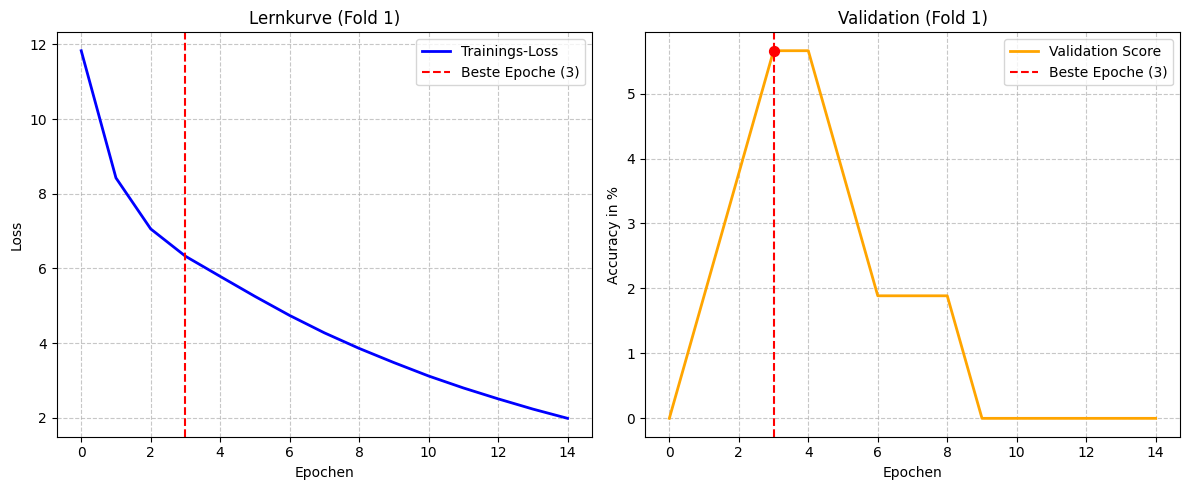


  🏋️ Trainiere Fold 2/5...
   🎯 Training gestoppt. Beste Gewichte aus Epoche 12!


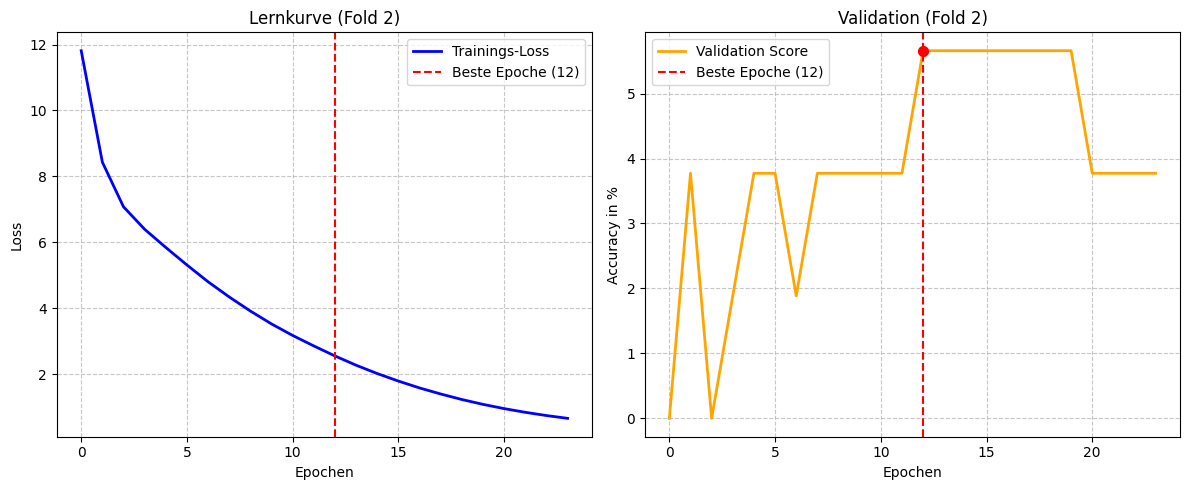


  🏋️ Trainiere Fold 3/5...
   🎯 Training gestoppt. Beste Gewichte aus Epoche 8!


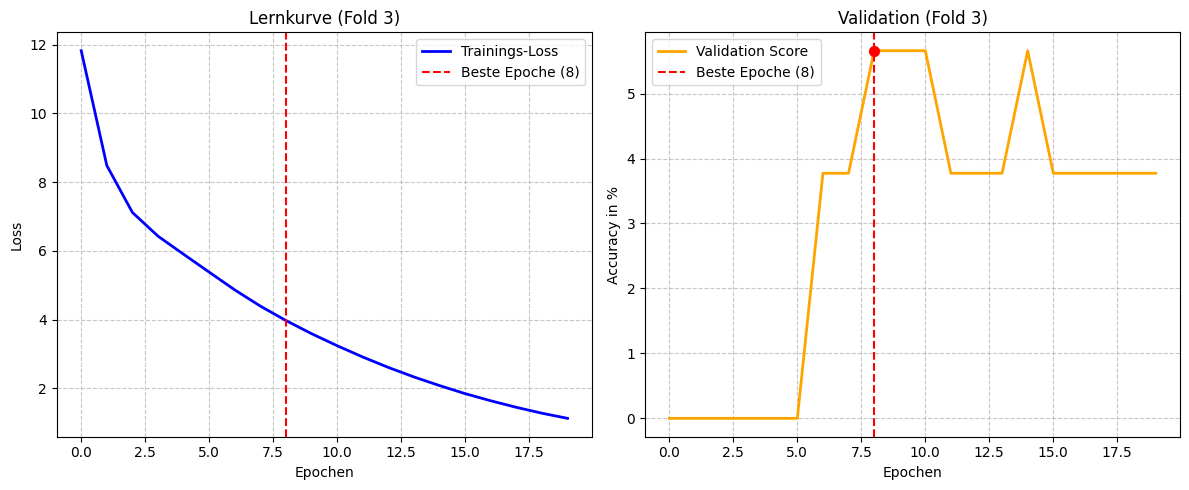


  🏋️ Trainiere Fold 4/5...
   🎯 Training gestoppt. Beste Gewichte aus Epoche 8!


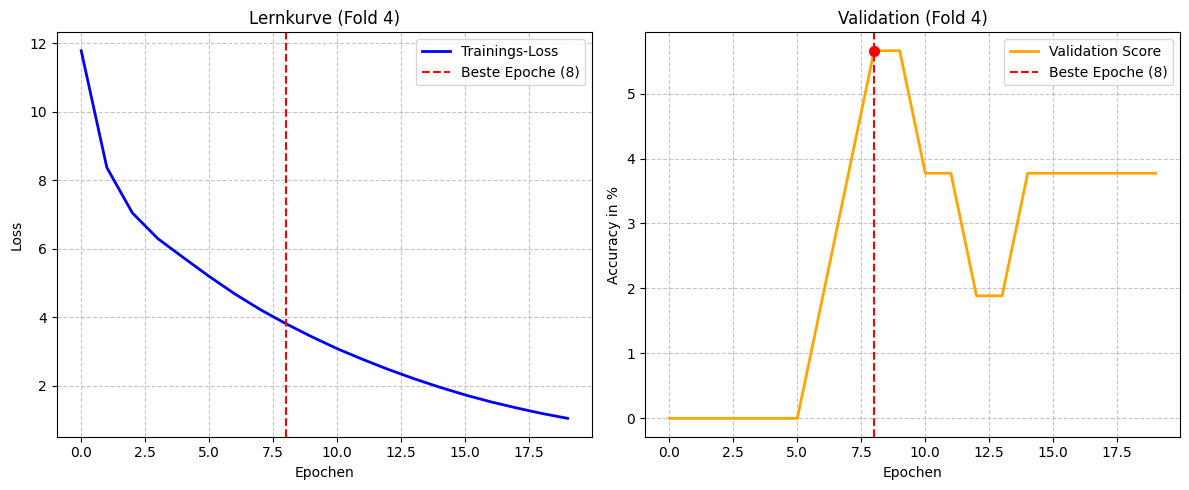


  🏋️ Trainiere Fold 5/5...
   🎯 Training gestoppt. Beste Gewichte aus Epoche 4!


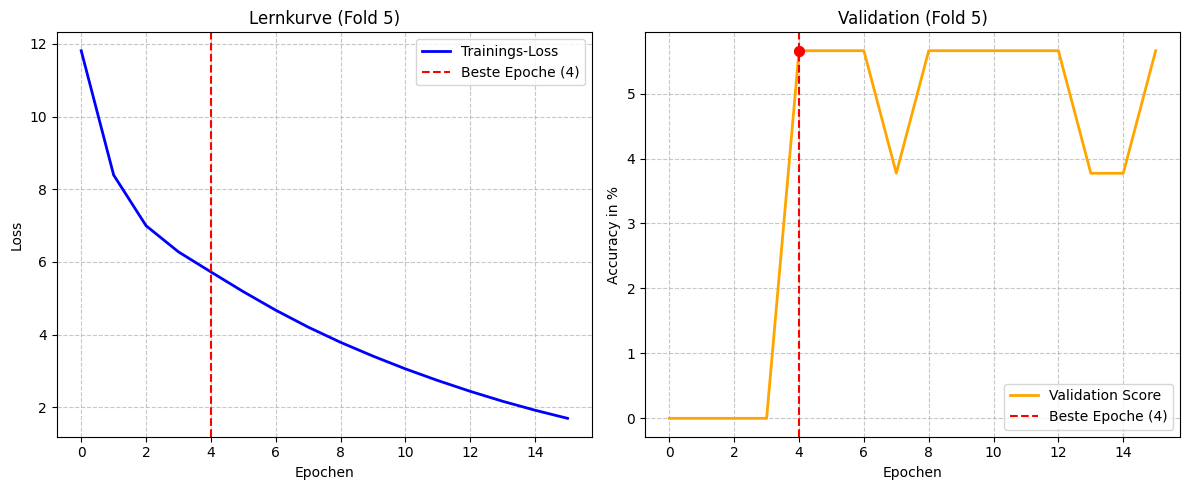

📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Cross-Validation):
                       precision    recall  f1-score   support

Algorithm Development       0.84      0.94      0.88       498
 Hardware Development       0.70      0.36      0.47       174
 Software Development       0.60      0.64      0.62       351
           User Study       0.76      0.79      0.77       389
        Dataset Paper       0.00      0.00      0.00        57
    Literature Review       0.00      0.00      0.00        12
     is_dataset_paper       0.00      0.00      0.00        18
          open_access       0.59      0.53      0.56       318
        code_required       0.88      0.99      0.93       569
       code_available       0.56      0.15      0.24       157
             code_url       0.45      0.14      0.21       172
        data_required       0.83      0.93      0.88       475
       data_available       0.65      0.45      0.53       202
             data_url       0.19      0.03      

In [22]:
"""
Sk.learn MLP mit impliziter Abhängigkeit, aber ohne explizite Abhängigkeit (Output-Knoten kennen nicht den gesamten Output Vektor)
Zweck dieser Zelle:
Klassifikation der Paper-Typen mittels Scikit-Learn (MLPClassifier).
Unterstützt flexibel entweder einen Holdout-Split (80/20) oder eine 
statistisch abgesicherte n-Fold Cross-Validation für Multi-Label-Daten.
Inklusive automatischer Run-Ordner-Generierung.
"""

import numpy as np
import json 
import pandas as pd
import random
import matplotlib.pyplot as plt  
from sklearn.preprocessing import StandardScaler # 🔄 NEU: Zwingend nötig für schnelles, tiefes Lernen!
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, hamming_loss, accuracy_score, jaccard_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

# --- CONFIG FÜR DIE EVALUIERUNG ---
VALIDIERUNGS_METHODE = "cross_validation" # "holdout" oder "cross_validation"
N_FOLDS = 5                               

# 🔄 NEU: DETERMINISTISCHER START (Analog zum Cockpit/PyTorch)
def set_deterministic_seeds(seed=42):
    """Fixiert alle Zufallsgeneratoren für absolute Reproduzierbarkeit."""
    random.seed(seed)
    np.random.seed(seed)
    print(f"🔒 Zufalls-Seed auf '{seed}' fixiert. Ergebnisse sind deterministisch!")

seed_to_use = globals().get('GLOBAL_SEED', 42)
set_deterministic_seeds(seed_to_use)

# --- 1. DATEN VOM AKTUELLEN STRATEGIE-ORDNER LADEN ---
X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')

with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    ML_COLUMNS = json.load(f)

# --- 2. AUTOMATISCHE RUN-ORDNER LOGIK ---
classifier_name = "Scikit_MLP_CrossVal" if VALIDIERUNGS_METHODE == "cross_validation" else "Scikit_MLP_Holdout"
base_dir = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
base_dir.mkdir(parents=True, exist_ok=True)

# Scanne den Ordner nach existierenden "Run_X" Ordnern und finde die höchste Nummer
existing_runs = [d.name for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("Run_")]
run_numbers = [int(name.split("_")[1]) for name in existing_runs if name.split("_")[1].isdigit()]
next_run = max(run_numbers) + 1 if run_numbers else 1

# Erstelle den neuen Arbeitsordner für diesen Durchlauf
RUN_DIR = base_dir / f"Run_{next_run}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(f"📊 Daten erfolgreich geladen (Pooling-Dimension: {X.shape[1]})")
print(f"⚙️ Gewählte Evaluierung: {VALIDIERUNGS_METHODE.upper()}")
print(f"📁 Neuer Arbeitsordner erstellt: {RUN_DIR}\n")

# --- HEADER FÜR DIE TXT-DATEI VORBEREITEN ---
report_header = (
    f"=== RUN PARAMETER ===\n"
    f"Datenquelle: {DATEN_QUELLE}\n"
    f"Embed-Modell: {MODELL_NAME}\n"
    f"Chunking-Strategie: {STRATEGIE_NAME}\n"
    f"Pooling: {POOLING_STRATEGIE}\n"
    f"Evaluierung: {VALIDIERUNGS_METHODE}\n"
    f"Zufalls-Seed: {seed_to_use}\n"
    f"Feature Scaling: StandardScaler (Mean=0, Var=1)\n"
    f"L2 Regulierung (Weight Decay): 1e-4\n"
    f"Checkpointing: Early Stopping auf Accuracy (Patience=10)\n"
    f"MLP-Dimensionen: (512, 256)\n"
    f"=====================\n\n"
)

def create_new_mlp():
    return MLPClassifier(
        hidden_layer_sizes=(512, 256),   
        learning_rate_init=0.0005,       
        alpha=1e-4,                      # 🔄 FIX: Standardisierte L2-Regulierung
        max_iter=600,                    
        early_stopping=True,             
        validation_fraction=0.1,         
        n_iter_no_change=10,             # 🔄 FIX: Auf 10 gesetzt, damit Early Stopping wirklich greifen kann!
        random_state=seed_to_use
    )

# --- 3. EVALUIERUNG - LOGIK ---
best_epochs_doku = []

if VALIDIERUNGS_METHODE == "holdout":
    # --- A: KLASSISCHER HOLDOUT SPLIT (80/20) ---
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_to_use) 
    
    # 🔄 NEU: Skalierung für Holdout
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    mlp = create_new_mlp()
    print("🏋️ Starte einmaliges MLP-Training (Holdout)...") 
    mlp.fit(X_train, y_train)

    # 🔄 NEU: Beste Epoche anhand des Validation Scores extrahieren
    best_epoch = np.argmax(mlp.validation_scores_)
    best_acc = mlp.validation_scores_[best_epoch] * 100
    best_epochs_doku.append(f"Holdout: Epoche {best_epoch} (Val-Accuracy: {best_acc:.2f}%)")
    print(f"   🎯 Training gestoppt. Beste Gewichte aus Epoche {best_epoch}!")

    # --- LERNKURVEN PLOTTEN ---
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(mlp.loss_curve_, label='Trainings-Loss', color='blue', linewidth=2)
    plt.axvline(x=best_epoch, color='red', linestyle='--', linewidth=1.5, label=f'Beste Epoche ({best_epoch})')
    plt.title("Lernkurve: Fehler minimieren")
    plt.xlabel("Epochen")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    
    plt.subplot(1, 2, 2)
    val_scores_percent = [score * 100 for score in mlp.validation_scores_]
    plt.plot(val_scores_percent, label='Validation Score', color='orange', linewidth=2)
    plt.axvline(x=best_epoch, color='red', linestyle='--', linewidth=1.5, label=f'Beste Epoche ({best_epoch})')
    plt.scatter(best_epoch, best_acc, color='red', s=50, zorder=5)
    plt.title("Validation: Generalisierung prüfen")
    plt.xlabel("Epochen")
    plt.ylabel("Accuracy in %")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    # Bild im Run-Ordner speichern
    graph_path = RUN_DIR / f"Run_{next_run}_Learning_Curve.png"
    plt.savefig(graph_path, dpi=300, bbox_inches='tight')
    plt.show() 
        
    predictions = mlp.predict(X_test) 
    
    # Auswertung zusammenbauen
    report_str = classification_report(y_test, predictions, target_names=ML_COLUMNS, zero_division=0)
    h_loss = hamming_loss(y_test, predictions) 
    exact_match = accuracy_score(y_test, predictions) 
    jaccard = jaccard_score(y_test, predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 KLASSIFIZIERUNGS-BERICHT (Holdout 80/20):
-----------------------------------------------------------------
{report_str}
-----------------------------------------------------------------
📌 Gewichts-Ursprung (Beste Epoche durch Early Stopping):
{best_epochs_doku[0]}
-----------------------------------------------------------------
📉 Hamming Loss: {h_loss:.4f}
🎯 Subset Accuracy (Exact Match Ratio): {exact_match:.4f} (Exakt {exact_match*100:.1f}% der Teststudien wurden fehlerfrei getroffen!)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} ({jaccard*100:.1f}%)
"""
    print(log_text)
    
    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y_test[:, i]
        daten_dict[f"{col_name}_pred"] = predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)

elif VALIDIERUNGS_METHODE == "cross_validation":
    # --- B: N-FOLD CROSS VALIDATION (STRATIFIZIERT) ---
    print(f"🔄 Starte {N_FOLDS}-Fold Multi-Label Cross-Validation...")
    
    mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed_to_use)
    
    oof_predictions = np.zeros_like(y)
    hamming_losses = []
    
    for fold, (train_idx, test_idx) in enumerate(mskf.split(X, y)):
        print(f"\n  🏋️ Trainiere Fold {fold + 1}/{N_FOLDS}...")
        
        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]
        
        # 🔄 NEU: Skalierung streng pro Fold (verhindert Data Leakage!)
        scaler = StandardScaler()
        X_train_fold = scaler.fit_transform(X_train_fold)
        X_test_fold = scaler.transform(X_test_fold)
        
        mlp_fold = create_new_mlp()
        mlp_fold.fit(X_train_fold, y_train_fold)

        # 🔄 NEU: Beste Epoche für diesen Fold extrahieren
        best_epoch = np.argmax(mlp_fold.validation_scores_)
        best_acc = mlp_fold.validation_scores_[best_epoch] * 100
        best_epochs_doku.append(f"Fold {fold+1}: Epoche {best_epoch} (Val-Accuracy: {best_acc:.2f}%)")
        print(f"   🎯 Training gestoppt. Beste Gewichte aus Epoche {best_epoch}!")

        # --- LERNKURVEN PLOTTEN ---
        plt.figure(figsize=(12, 5))
        
        plt.subplot(1, 2, 1)
        plt.plot(mlp_fold.loss_curve_, label='Trainings-Loss', color='blue', linewidth=2)
        plt.axvline(x=best_epoch, color='red', linestyle='--', linewidth=1.5, label=f'Beste Epoche ({best_epoch})')
        plt.title(f"Lernkurve (Fold {fold+1})")
        plt.xlabel("Epochen")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)
        
        plt.subplot(1, 2, 2)
        val_scores_percent = [score * 100 for score in mlp_fold.validation_scores_]
        plt.plot(val_scores_percent, label='Validation Score', color='orange', linewidth=2)
        plt.axvline(x=best_epoch, color='red', linestyle='--', linewidth=1.5, label=f'Beste Epoche ({best_epoch})')
        plt.scatter(best_epoch, best_acc, color='red', s=50, zorder=5)
        plt.title(f"Validation (Fold {fold+1})")
        plt.xlabel("Epochen")
        plt.ylabel("Accuracy in %")
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        
        # Bild direkt im spezifischen Run-Ordner speichern
        graph_path = RUN_DIR / f"Run_{next_run}_Learning_Curve_Fold-{fold+1}.png"
        plt.savefig(graph_path, dpi=300, bbox_inches='tight')
        plt.show() 
        
        fold_preds = mlp_fold.predict(X_test_fold)
        oof_predictions[test_idx] = fold_preds
        hamming_losses.append(hamming_loss(y_test_fold, fold_preds))
    
    # Auswertung zusammenbauen
    report_str = classification_report(y, oof_predictions, target_names=ML_COLUMNS, zero_division=0)
    mean_hamming = np.mean(hamming_losses)
    std_hamming = np.std(hamming_losses)
    exact_match = accuracy_score(y, oof_predictions)
    jaccard = jaccard_score(y, oof_predictions, average='samples', zero_division=0)
    
    epochs_doku_str = "\n".join(best_epochs_doku)
    
    log_text = f"""📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Cross-Validation):
=================================================================
{report_str}
=================================================================
📌 Gewichts-Ursprung (Beste Epochen durch Accuracy Early Stopping):
{epochs_doku_str}
-----------------------------------------------------------------
📉 Mittlerer Hamming Loss: {mean_hamming:.4f} (± {std_hamming:.4f})
🎯 Subset Accuracy (Exact Match Ratio): {exact_match:.4f} (Exakt {exact_match*100:.1f}% aller Studien wurden absolut fehlerfrei getroffen!)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} (Das Modell trifft im Schnitt {jaccard*100:.1f}% der relevanten Labels pro Studie!)
"""
    print(log_text)

    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y[:, i]
        daten_dict[f"{col_name}_pred"] = oof_predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"\n💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

In [23]:
"""
Zweck dieser Zelle:
Klassifikation der Paper-Typen und Metadaten (16 Labels).
LÖSUNG FÜR KLASSEN-UNGLEICHGEWICHT: Nutzt den MultiOutputClassifier in Kombination 
mit Random Forests (Binary Relevance). So wird für jedes der 16 Labels ein eigener 
Spezialist trainiert, der das Klassen-Ungleichgewicht isoliert ausgleichen kann.

"""

import numpy as np
import json
import pandas as pd  
import random
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, hamming_loss, accuracy_score, jaccard_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

# --- CONFIG FÜR DIE EVALUIERUNG ---
VALIDIERUNGS_METHODE = "cross_validation" # "holdout" oder "cross_validation"
N_FOLDS = 5                              

# DETERMINISTISCHER START
def set_deterministic_seeds(seed=42):
    """Fixiert alle Zufallsgeneratoren für absolute Reproduzierbarkeit."""
    random.seed(seed)
    np.random.seed(seed)
    print(f"🔒 Zufalls-Seed auf '{seed}' fixiert. Ergebnisse sind deterministisch!")

seed_to_use = globals().get('GLOBAL_SEED', 42)
set_deterministic_seeds(seed_to_use)

# --- 1. DATEN LADEN ---
X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')

with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    ML_COLUMNS = json.load(f)

# --- 2. AUTOMATISCHE RUN-ORDNER LOGIK ---
# 🔄 GEÄNDERT: Statischer Name, damit alle Runs (Holdout & CrossVal) im selben Ordner landen!
classifier_name = "RandomForest_MultiOutput" 

base_dir = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
base_dir.mkdir(parents=True, exist_ok=True)

existing_runs = [d.name for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("Run_")]
run_numbers = [int(name.split("_")[1]) for name in existing_runs if name.split("_")[1].isdigit()]
next_run = max(run_numbers) + 1 if run_numbers else 1

RUN_DIR = base_dir / f"Run_{next_run}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(f"📊 Daten geladen (Studien: {X.shape[0]}, Features: {X.shape[1]}, Labels: {y.shape[1]})")
print(f"⚙️ Gewählte Evaluierung: {VALIDIERUNGS_METHODE.upper()}")
print(f"📁 Neuer Arbeitsordner erstellt: {RUN_DIR}\n")

# --- HEADER FÜR DIE TXT-DATEI VORBEREITEN ---
report_header = (
    f"=== RUN PARAMETER ===\n"
    f"Datenquelle: {DATEN_QUELLE}\n"
    f"Embed-Modell: {MODELL_NAME}\n"
    f"Chunking-Strategie: {STRATEGIE_NAME}\n"
    f"Pooling: {POOLING_STRATEGIE}\n"
    f"Evaluierung: {VALIDIERUNGS_METHODE}\n"
    f"Klassifikator: {classifier_name}\n"
    f"Zufalls-Seed: {seed_to_use}\n"
    f"Feature Scaling: StandardScaler (für Pipeline-Konsistenz)\n"
    f"Architektur: Binary Relevance (16 separierte RF-Modelle)\n"
    f"Bäume pro Label: 150 (max_depth=15)\n"
    f"Class Weighting: Balanced\n"
    f"=====================\n\n"
)

# --- 3. MODELL DEFINIEREN (Das Spezialisten-Team) ---
def create_specialist_team():
    base_rf = RandomForestClassifier(
        n_estimators=150,           # 150 Entscheidungsbäume pro Label
        class_weight="balanced",    # Gleicht seltene Klassen automatisch aus
        max_depth=15,               # Verhindert zu starkes Overfitting
        random_state=seed_to_use,
        n_jobs=-1                   # Nutzt alle CPU-Kerne
    )
    return MultiOutputClassifier(base_rf)

# --- 4. EVALUIERUNG - LOGIK ---

if VALIDIERUNGS_METHODE == "holdout":
    # --- A: KLASSISCHER HOLDOUT SPLIT (80/20) ---
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_to_use)
    
    # Skalierung (Für RF nicht strikt nötig, aber sichert 100% Vergleichbarkeit der Pipelines)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    clf = create_specialist_team()
    print("🏋️ Starte einmaliges Training des RF-Spezialisten-Teams (Holdout)...")
    clf.fit(X_train, y_train)
    
    predictions = clf.predict(X_test)
    
    # Auswertung
    report_str = classification_report(y_test, predictions, target_names=ML_COLUMNS, zero_division=0)
    h_loss = hamming_loss(y_test, predictions)
    exact_match = accuracy_score(y_test, predictions)
    jaccard = jaccard_score(y_test, predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 KLASSIFIZIERUNGS-BERICHT (Holdout 80/20):
=================================================================
{report_str}
=================================================================
📉 Hamming Loss: {h_loss:.4f}
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} ({jaccard*100:.1f}%)
"""
    print(log_text)
    
    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y_test[:, i]
        daten_dict[f"{col_name}_pred"] = predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"\n💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

elif VALIDIERUNGS_METHODE == "cross_validation":
    # --- B: N-FOLD CROSS VALIDATION ---
    print(f"🔄 Starte {N_FOLDS}-Fold Multi-Label Cross-Validation mit isolierten Random Forests...")
    
    mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed_to_use)
    
    oof_predictions = np.zeros_like(y)
    hamming_losses = []
    
    for fold, (train_idx, test_idx) in enumerate(mskf.split(X, y)):
        print(f"  🌲 Wachse Wald für Fold {fold + 1}/{N_FOLDS}...")
        
        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]
        
        # Skalierung pro Fold (verhindert Data Leakage!)
        scaler = StandardScaler()
        X_train_fold = scaler.fit_transform(X_train_fold)
        X_test_fold = scaler.transform(X_test_fold)
        
        clf_fold = create_specialist_team()
        clf_fold.fit(X_train_fold, y_train_fold)
        
        fold_preds = clf_fold.predict(X_test_fold)
        oof_predictions[test_idx] = fold_preds
        hamming_losses.append(hamming_loss(y_test_fold, fold_preds))
    
    # Auswertung zusammenbauen
    report_str = classification_report(y, oof_predictions, target_names=ML_COLUMNS, zero_division=0)
    mean_hamming = np.mean(hamming_losses)
    std_hamming = np.std(hamming_losses)
    exact_match = accuracy_score(y, oof_predictions)
    jaccard = jaccard_score(y, oof_predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Binary Relevance Random Forest):
=================================================================
{report_str}
=================================================================
📉 Mittlerer Hamming Loss: {mean_hamming:.4f} (± {std_hamming:.4f})
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} (Das Modell trifft im Schnitt {jaccard*100:.1f}% der relevanten Labels pro Studie!)
"""
    print("\n" + log_text)

    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y[:, i]
        daten_dict[f"{col_name}_pred"] = oof_predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

🔒 Zufalls-Seed auf '42' fixiert. Ergebnisse sind deterministisch!
📊 Daten geladen (Studien: 654, Features: 768, Labels: 16)
⚙️ Gewählte Evaluierung: CROSS_VALIDATION
📁 Neuer Arbeitsordner erstellt: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/Predictions/RandomForest_MultiOutput/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/Run_5

🔄 Starte 5-Fold Multi-Label Cross-Validation mit isolierten Random Forests...
  🌲 Wachse Wald für Fold 1/5...
  🌲 Wachse Wald für Fold 2/5...
  🌲 Wachse Wald für Fold 3/5...
  🌲 Wachse Wald für Fold 4/5...
  🌲 Wachse Wald für Fold 5/5...

📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Binary Relevance Random Forest):
                       precision    recall  f1-score   support

Algorithm Development       0.78      1.00      0.87       498
 Hardware Development       0.75      0.02      0.03       174
 Software Development       0.56      0.77      0.65       351
           User Study       0.71      0.90      0.79       389
        D

In [32]:
"""
Zweck dieser Zelle:
Klassifikation der Paper-Typen und Metadaten (16 Labels).
LÖSUNG FÜR KLASSEN-UNGLEICHGEWICHT: Nutzt den MultiOutputClassifier in Kombination 
mit Random Forests (Binary Relevance). So wird für jedes der 16 Labels ein eigener 
Spezialist trainiert, der das Klassen-Ungleichgewicht isoliert ausgleichen kann.

"""

import numpy as np
import json
import pandas as pd  
import random
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, hamming_loss, accuracy_score, jaccard_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

# --- CONFIG FÜR DIE EVALUIERUNG ---
VALIDIERUNGS_METHODE = "cross_validation" # "holdout" oder "cross_validation"
N_FOLDS = 5                              

# DETERMINISTISCHER START
def set_deterministic_seeds(seed=42):
    """Fixiert alle Zufallsgeneratoren für absolute Reproduzierbarkeit."""
    random.seed(seed)
    np.random.seed(seed)
    print(f"🔒 Zufalls-Seed auf '{seed}' fixiert. Ergebnisse sind deterministisch!")

seed_to_use = globals().get('GLOBAL_SEED', 42)
set_deterministic_seeds(seed_to_use)

# --- 1. DATEN LADEN ---
X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')

with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    ML_COLUMNS = json.load(f)

# --- 2. AUTOMATISCHE RUN-ORDNER LOGIK ---
# 🔄 GEÄNDERT: Statischer Name, damit alle Runs (Holdout & CrossVal) im selben Ordner landen!
classifier_name = "RandomForest_MultiOutput" 

base_dir = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
base_dir.mkdir(parents=True, exist_ok=True)

existing_runs = [d.name for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("Run_")]
run_numbers = [int(name.split("_")[1]) for name in existing_runs if name.split("_")[1].isdigit()]
next_run = max(run_numbers) + 1 if run_numbers else 1

RUN_DIR = base_dir / f"Run_{next_run}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(f"📊 Daten geladen (Studien: {X.shape[0]}, Features: {X.shape[1]}, Labels: {y.shape[1]})")
print(f"⚙️ Gewählte Evaluierung: {VALIDIERUNGS_METHODE.upper()}")
print(f"📁 Neuer Arbeitsordner erstellt: {RUN_DIR}\n")

# --- HEADER FÜR DIE TXT-DATEI VORBEREITEN ---
report_header = (
    f"=== RUN PARAMETER ===\n"
    f"Datenquelle: {DATEN_QUELLE}\n"
    f"Embed-Modell: {MODELL_NAME}\n"
    f"Chunking-Strategie: {STRATEGIE_NAME}\n"
    f"Pooling: {POOLING_STRATEGIE}\n"
    f"Evaluierung: {VALIDIERUNGS_METHODE}\n"
    f"Klassifikator: {classifier_name}\n"
    f"Zufalls-Seed: {seed_to_use}\n"
    f"Feature Scaling: StandardScaler (für Pipeline-Konsistenz)\n"
    f"Architektur: Binary Relevance (16 separierte RF-Modelle)\n"
    f"Bäume pro Label: 150 (max_depth=15)\n"
    f"Class Weighting: Balanced\n"
    f"=====================\n\n"
)

# --- 3. MODELL DEFINIEREN (Das Spezialisten-Team) ---
def create_specialist_team():
    base_rf = RandomForestClassifier(
        n_estimators=150,           # 150 Entscheidungsbäume pro Label
        class_weight="balanced",    # Gleicht seltene Klassen automatisch aus
        max_depth=15,               # Verhindert zu starkes Overfitting
        random_state=seed_to_use,
        n_jobs=-1                   # Nutzt alle CPU-Kerne
    )
    return MultiOutputClassifier(base_rf)

# --- 4. EVALUIERUNG - LOGIK ---

if VALIDIERUNGS_METHODE == "holdout":
    # --- A: KLASSISCHER HOLDOUT SPLIT (80/20) ---
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_to_use)
    
    # Skalierung (Für RF nicht strikt nötig, aber sichert 100% Vergleichbarkeit der Pipelines)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    clf = create_specialist_team()
    print("🏋️ Starte einmaliges Training des RF-Spezialisten-Teams (Holdout)...")
    clf.fit(X_train, y_train)
    
    predictions = clf.predict(X_test)
    
    # Auswertung
    report_str = classification_report(y_test, predictions, target_names=ML_COLUMNS, zero_division=0)
    h_loss = hamming_loss(y_test, predictions)
    exact_match = accuracy_score(y_test, predictions)
    jaccard = jaccard_score(y_test, predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 KLASSIFIZIERUNGS-BERICHT (Holdout 80/20):
=================================================================
{report_str}
=================================================================
📉 Hamming Loss: {h_loss:.4f}
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} ({jaccard*100:.1f}%)
"""
    print(log_text)
    
    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y_test[:, i]
        daten_dict[f"{col_name}_pred"] = predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"\n💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

elif VALIDIERUNGS_METHODE == "cross_validation":
    # --- B: N-FOLD CROSS VALIDATION ---
    print(f"🔄 Starte {N_FOLDS}-Fold Multi-Label Cross-Validation mit isolierten Random Forests...")
    
    mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed_to_use)
    
    oof_predictions = np.zeros_like(y)
    hamming_losses = []
    
    for fold, (train_idx, test_idx) in enumerate(mskf.split(X, y)):
        print(f"  🌲 Wachse Wald für Fold {fold + 1}/{N_FOLDS}...")
        
        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]
        
        # Skalierung pro Fold (verhindert Data Leakage!)
        scaler = StandardScaler()
        X_train_fold = scaler.fit_transform(X_train_fold)
        X_test_fold = scaler.transform(X_test_fold)
        
        clf_fold = create_specialist_team()
        clf_fold.fit(X_train_fold, y_train_fold)
        
        fold_preds = clf_fold.predict(X_test_fold)
        oof_predictions[test_idx] = fold_preds
        hamming_losses.append(hamming_loss(y_test_fold, fold_preds))
    
    # Auswertung zusammenbauen
    report_str = classification_report(y, oof_predictions, target_names=ML_COLUMNS, zero_division=0)
    mean_hamming = np.mean(hamming_losses)
    std_hamming = np.std(hamming_losses)
    exact_match = accuracy_score(y, oof_predictions)
    jaccard = jaccard_score(y, oof_predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Binary Relevance Random Forest):
=================================================================
{report_str}
=================================================================
📉 Mittlerer Hamming Loss: {mean_hamming:.4f} (± {std_hamming:.4f})
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} (Das Modell trifft im Schnitt {jaccard*100:.1f}% der relevanten Labels pro Studie!)
"""
    print("\n" + log_text)

    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y[:, i]
        daten_dict[f"{col_name}_pred"] = oof_predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

🔒 Zufalls-Seed auf '42' fixiert. Ergebnisse sind deterministisch!
📊 Daten geladen (Studien: 654, Features: 768, Labels: 16)
⚙️ Gewählte Evaluierung: CROSS_VALIDATION
📁 Neuer Arbeitsordner erstellt: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/Predictions/RandomForest_MultiOutput/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/Run_8

🔄 Starte 5-Fold Multi-Label Cross-Validation mit isolierten Random Forests...
  🌲 Wachse Wald für Fold 1/5...
  🌲 Wachse Wald für Fold 2/5...
  🌲 Wachse Wald für Fold 3/5...
  🌲 Wachse Wald für Fold 4/5...
  🌲 Wachse Wald für Fold 5/5...

📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Binary Relevance Random Forest):
                       precision    recall  f1-score   support

Algorithm Development       0.78      1.00      0.87       498
 Hardware Development       0.75      0.02      0.03       174
 Software Development       0.56      0.77      0.65       351
           User Study       0.71      0.90      0.79       389
        D

🔒 Zufalls-Seed auf '42' fixiert. Ergebnisse sind deterministisch!
🚀 Starte PyTorch Training auf Device: cpu
📊 Daten geladen (Studien: 654, Features: 768, Labels: 16)
📁 Neuer Arbeitsordner erstellt: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/Predictions/PyTorch_BCE_MLP/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/Run_18

 Trainiere Fold 1/5...
   🎯 Beste Gewichte in Epoche 99 gefunden (Validation-Loss: 0.6798)


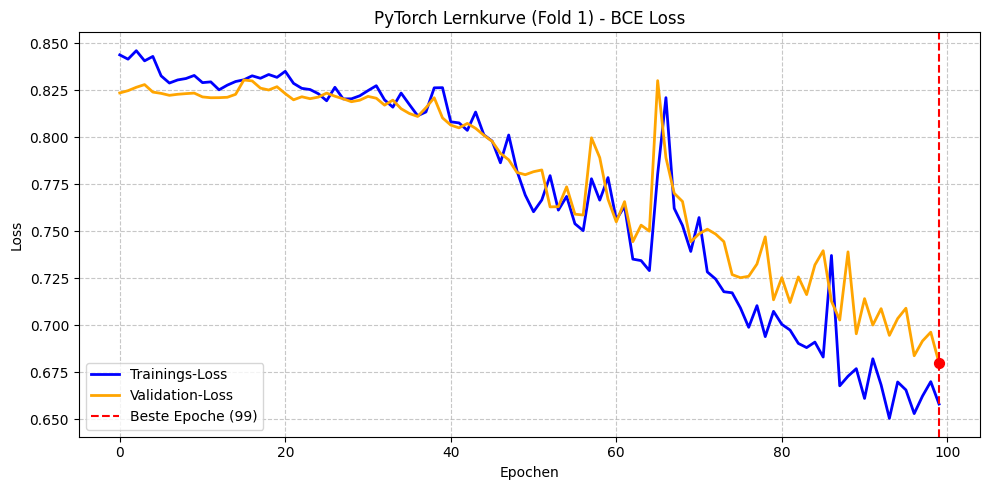

 Trainiere Fold 2/5...
   🎯 Beste Gewichte in Epoche 71 gefunden (Validation-Loss: 0.7187)


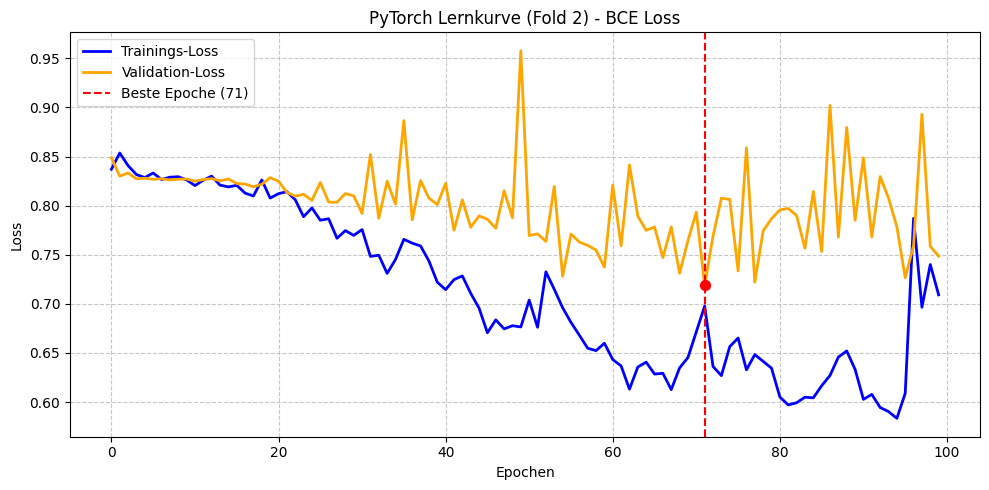

 Trainiere Fold 3/5...
   🎯 Beste Gewichte in Epoche 97 gefunden (Validation-Loss: 0.7202)


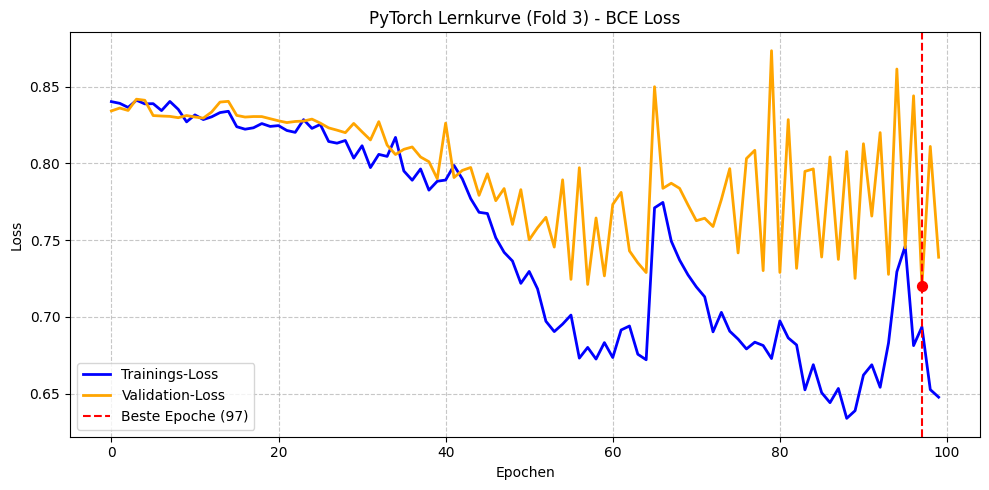

 Trainiere Fold 4/5...
   🎯 Beste Gewichte in Epoche 93 gefunden (Validation-Loss: 0.7310)


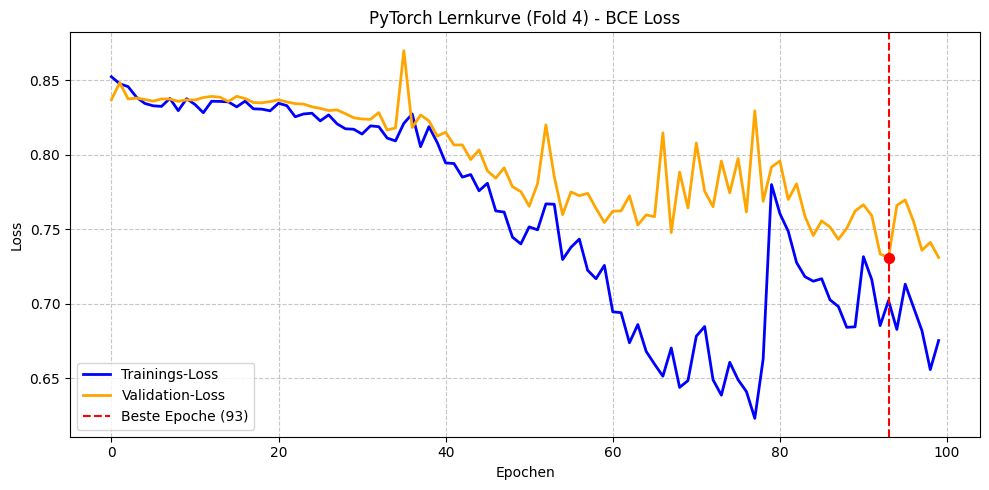

 Trainiere Fold 5/5...
   🎯 Beste Gewichte in Epoche 73 gefunden (Validation-Loss: 0.6901)


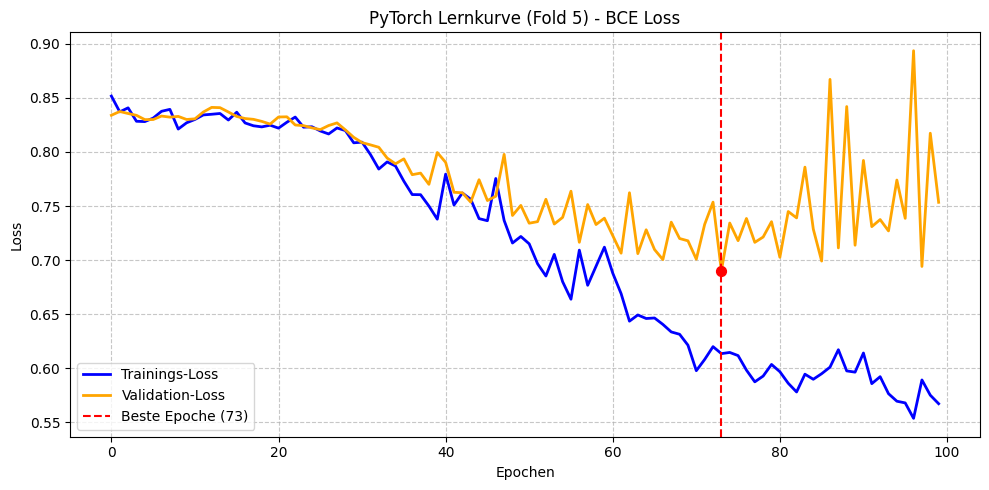


📊 REPRODUZIERBARER GESAMT-BERICHT (PyTorch MLP mit pos_weight):
                       precision    recall  f1-score   support

Algorithm Development       0.93      0.69      0.79       498
 Hardware Development       0.44      0.66      0.53       174
 Software Development       0.54      0.46      0.50       351
           User Study       0.75      0.65      0.70       389
        Dataset Paper       0.18      0.67      0.29        57
    Literature Review       0.06      0.67      0.11        12
     is_dataset_paper       0.11      0.78      0.19        18
          open_access       0.58      0.63      0.61       318
        code_required       0.97      0.72      0.83       569
       code_available       0.36      0.59      0.44       157
             code_url       0.38      0.60      0.47       172
        data_required       0.91      0.74      0.82       475
       data_available       0.55      0.71      0.62       202
             data_url       0.31      0.63      0.42

In [38]:
"""
PYTORCH MLP
Zweck dieser Zelle:
Klassifikation der Paper-Typen und Metadaten (16 Labels) mit PyTorch.
LÖSUNG FÜR KLASSEN-UNGLEICHGEWICHT: Nutzt ein Multi-Label MLP mit BCEWithLogitsLoss 
und individuellen `pos_weight` Tensoren pro Klasse.
Inklusive automatischer Run-Ordner-Generierung und detaillierten Lernkurven (Train vs. Val).

🔄 NEU: Speichert die Knoten-Gewichte beim niedrigsten Validation-Loss (Checkpointing)
und stellt diese vor der finalen Vorhersage am Ende jedes Folds wieder her.
"""

import numpy as np
import json
import pandas as pd  
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt 
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, hamming_loss, accuracy_score
from sklearn.metrics import jaccard_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from tqdm import tqdm
import random
import copy # 🔄 NEU: Für das tiefe Kopieren der Modellgewichte im RAM

# --- CONFIG ---
N_FOLDS = 5
EPOCHS = 100
BATCH_SIZE = 128
VALIDIERUNGS_METHODE = "cross_validation"
NUTZE_GEWICHTUNG = True
lr=0.001 #Statische Learning-Rate

# DETERMINISTISCHER START (Übernahme aus dem Cockpit)
def set_deterministic_seeds(seed):
    """Fixiert alle Zufallsgeneratoren für absolute Reproduzierbarkeit."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"🔒 Zufalls-Seed auf '{seed}' fixiert. Ergebnisse sind deterministisch!")

seed_to_use = globals().get('GLOBAL_SEED', 42)
set_deterministic_seeds(seed_to_use)

# --- 1. DATEN LADEN ---
X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')

with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    ML_COLUMNS = json.load(f)

# --- Verzeichnis Bezeichnung und Logik ---
classifier_name = "PyTorch_BCE_MLP"

# Die tiefe Verzeichnisstruktur analog zu den Fusionsdaten
base_dir = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
base_dir.mkdir(parents=True, exist_ok=True)

# Scanne das Verzeichnis nach dem höchsten x in Unterverzeichnissen Run x, x >= 1
existing_runs = [d.name for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("Run_")]
run_numbers = [int(name.split("_")[1]) for name in existing_runs if name.split("_")[1].isdigit()]
next_run = max(run_numbers) + 1 if run_numbers else 1

# Erstelle Ordner Run x+1 
RUN_DIR = base_dir / f"Run_{next_run}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Starte PyTorch Training auf Device: {DEVICE}")
print(f"📊 Daten geladen (Studien: {X.shape[0]}, Features: {X.shape[1]}, Labels: {y.shape[1]})")
print(f"📁 Neuer Arbeitsordner erstellt: {RUN_DIR}\n")

# --- HEADER FÜR DIE TXT-DATEI VORBEREITEN ---
report_header = (
    f"=== RUN PARAMETER ===\n"
    f"Datenquelle: {DATEN_QUELLE}\n"
    f"Embed-Modell: {MODELL_NAME}\n"
    f"Chunking-Strategie: {STRATEGIE_NAME}\n"
    f"Pooling: {POOLING_STRATEGIE}\n"
    f"Evaluierung: {VALIDIERUNGS_METHODE}\n"
    f"Klassifikator: {classifier_name}\n"
    f"Zufalls-Seed: {seed_to_use}\n"
    f"Gewichtung (pos_weight): {NUTZE_GEWICHTUNG}\n"
    f"Epochen: {EPOCHS}\n"
    f"Batch Size: {BATCH_SIZE}\n"
    f"Learning Rate: {lr}\n"
    f"N-Folds : {N_FOLDS}\n"
    f"=====================\n\n"
)

# --- 3. PYTORCH DATASET DEFINIEREN ---
class PaperDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.float32)
        
    def __len__(self):
        return len(self.features)
        
    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

# --- 4. DAS NEURONALE NETZ (MLP) ---
class MultiLabelMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(MultiLabelMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3), # Verhindert Overfitting
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, output_dim) # Keine Sigmoid hier! Das macht BCEWithLogitsLoss
        )

    def forward(self, x):
        return self.network(x)

# --- 5. CROSS VALIDATION SCHLEIFE ---
mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed_to_use)
oof_predictions = np.zeros_like(y)
hamming_losses = []
best_epochs_per_fold = [] # 🔄 NEU: Speichert die beste Epoche für jeden Fold

for fold, (train_idx, test_idx) in enumerate(mskf.split(X, y)):
    print(f" Trainiere Fold {fold + 1}/{N_FOLDS}...")
    
    # Daten vorbereiten
    train_dataset = PaperDataset(X[train_idx], y[train_idx])
    test_dataset = PaperDataset(X[test_idx], y[test_idx])
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    # ⚖️ BERECHNUNG DER KLASSENGEWICHTE (pos_weight)
    y_train_fold = y[train_idx]
    pos_counts = np.sum(y_train_fold, axis=0)
    neg_counts = len(y_train_fold) - pos_counts
    pos_counts = np.clip(pos_counts, 1, None)
    pos_weights = torch.tensor(neg_counts / pos_counts, dtype=torch.float32).to(DEVICE)
    
    # Modell, Loss & Optimizer initialisieren
    model = MultiLabelMLP(input_dim=X.shape[1], output_dim=y.shape[1]).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights) 
    optimizer = optim.Adam(model.parameters(), lr)
    
    # LISTEN FÜR LERNKURVEN ---
    fold_train_losses = []
    fold_val_losses = []
    
    # 🔄 NEU: Checkpointing-Variablen initialisieren
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    best_epoch = 0
    
    # --- TRAINING & LIVES-TRACKING DER EPOCHEN ---
    for epoch in range(EPOCHS):
        # 1. Training Pass
        model.train()
        running_train_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * batch_x.size(0)
            
        epoch_train_loss = running_train_loss / len(train_dataset)
        fold_train_losses.append(epoch_train_loss)
        
        # 2. Validation Pass (Messen, ohne Gewichte anzufassen!)
        model.eval()
        running_val_loss = 0.0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
                logits = model(batch_x)
                val_loss = criterion(logits, batch_y)
                running_val_loss += val_loss.item() * batch_x.size(0)
                
        epoch_val_loss = running_val_loss / len(test_dataset)
        fold_val_losses.append(epoch_val_loss)

        # 🔄 NEU: Checkpointing - Halte Gewichte der besten Epoche fest
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            best_epoch = epoch

    best_epochs_per_fold.append(best_epoch) # 🔄 NEU: Merke beste Epoche
    print(f"   🎯 Beste Gewichte in Epoche {best_epoch} gefunden (Validation-Loss: {best_val_loss:.4f})")

    # --- LERNKURVEN PLOTTEN ---
    plt.figure(figsize=(10, 5))
    plt.plot(fold_train_losses, label='Trainings-Loss', color='blue', linewidth=2)
    plt.plot(fold_val_losses, label='Validation-Loss', color='orange', linewidth=2)
    
    # 🔄 NEU: Zeichne eine vertikale rote Checkpoint-Linie im Plot ein
    plt.axvline(x=best_epoch, color='red', linestyle='--', linewidth=1.5, 
                label=f'Beste Epoche ({best_epoch})')
    plt.scatter(best_epoch, best_val_loss, color='red', s=50, zorder=5)
    
    plt.title(f"PyTorch Lernkurve (Fold {fold+1}) - BCE Loss")
    plt.xlabel("Epochen")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    # Bild direkt im spezifischen Run-Ordner speichern
    graph_path = RUN_DIR / f"Run_{next_run}_Learning_Curve_Fold-{fold+1}.png"
    plt.savefig(graph_path, dpi=300, bbox_inches='tight')
    plt.show() 

    # --- FINALE EVALUIERUNG (Vorhersagen speichern) ---
    # 🔄 NEU: Stelle die besten Gewichte vor der Out-Of-Fold Vorhersage wieder her!
    model.load_state_dict(best_model_wts)
    model.eval()
    fold_preds = []
    with torch.no_grad():
        for batch_x, _ in test_loader:
            batch_x = batch_x.to(DEVICE)
            logits = model(batch_x)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).int().cpu().numpy()
            fold_preds.extend(preds)
            
    fold_preds = np.array(fold_preds)
    oof_predictions[test_idx] = fold_preds
    hamming_losses.append(hamming_loss(y[test_idx], fold_preds))

# --- 6. AUSWERTUNG ---
# 1. Metriken berechnen
report_str = classification_report(y, oof_predictions, target_names=ML_COLUMNS, zero_division=0)
mean_hamming = np.mean(hamming_losses)
std_hamming = np.std(hamming_losses)
exact_match = accuracy_score(y, oof_predictions)
jaccard = jaccard_score(y, oof_predictions, average='samples', zero_division=0)

# 🔄 NEU: Zusammenfassung der besten Epochen für den Report
epochs_doku = ", ".join([f"Fold {i+1}: Epoche {ep}" for i, ep in enumerate(best_epochs_per_fold)])

# 2. Den Konsolen-Text als großen String zusammenbauen
log_text = f"""📊 REPRODUZIERBARER GESAMT-BERICHT (PyTorch MLP mit pos_weight):
=================================================================
{report_str}
=================================================================
📌 Gewichts-Ursprung (Beste Epochen pro Fold):
{epochs_doku}
-----------------------------------------------------------------
📉 Mittlerer Hamming Loss: {mean_hamming:.4f} (± {std_hamming:.4f})
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity:  {jaccard:.4f} (Das Modell trifft im Schnitt {jaccard*100:.1f}% der relevanten Labels pro Studie!)
"""

# 3. Einmal in der Konsole anzeigen
print("\n" + log_text)

# --- 7. DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
daten_dict = {}
for i, col_name in enumerate(ML_COLUMNS):
    daten_dict[f"{col_name}_true"] = y[:, i]
    daten_dict[f"{col_name}_pred"] = oof_predictions[:, i]
pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)

with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
    f.write(report_header + log_text)

print(f"💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
print(f"📂 Zu finden unter: {RUN_DIR}")

🔒 Globaler Zufalls-Seed auf '42' fixiert. Ergebnisse sind jetzt deterministisch!
🚀 Starte PyTorch Training auf Device: cpu
📊 Daten geladen (Studien: 654, Features: 768, Labels: 16)
📁 Neuer Arbeitsordner erstellt: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/Predictions/PyTorch_BCE_MLP_Balanced/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/Run_8

🏋️ Trainiere Fold 1/10...
   🎯 Beste Gewichte in Epoche 40 gefunden (Validation-Loss: 0.6246)


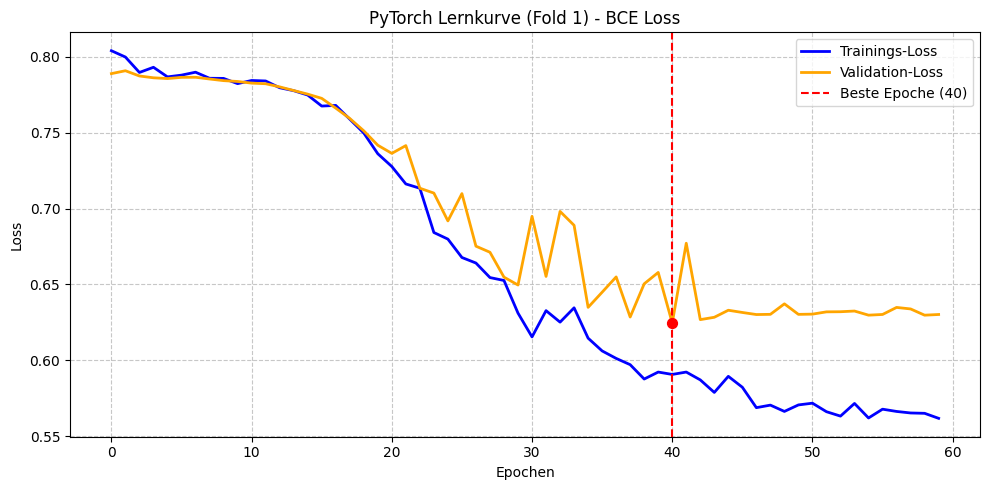

🏋️ Trainiere Fold 2/10...
   🎯 Beste Gewichte in Epoche 37 gefunden (Validation-Loss: 0.6958)


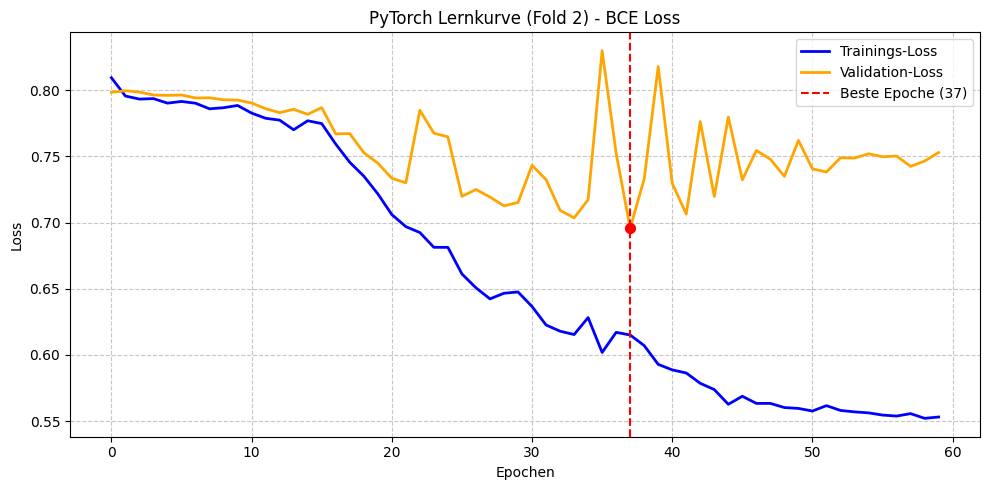

🏋️ Trainiere Fold 3/10...
   🎯 Beste Gewichte in Epoche 28 gefunden (Validation-Loss: 0.6719)


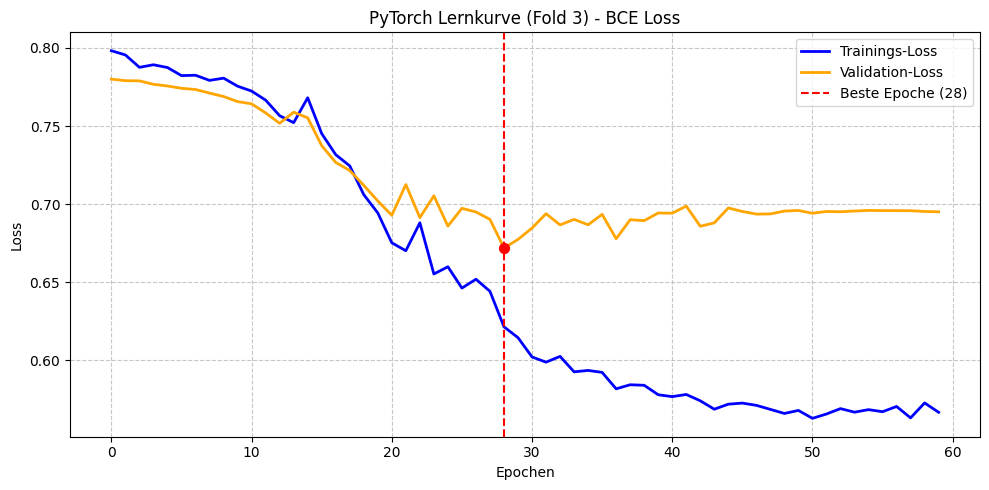

🏋️ Trainiere Fold 4/10...
   🎯 Beste Gewichte in Epoche 21 gefunden (Validation-Loss: 0.7468)


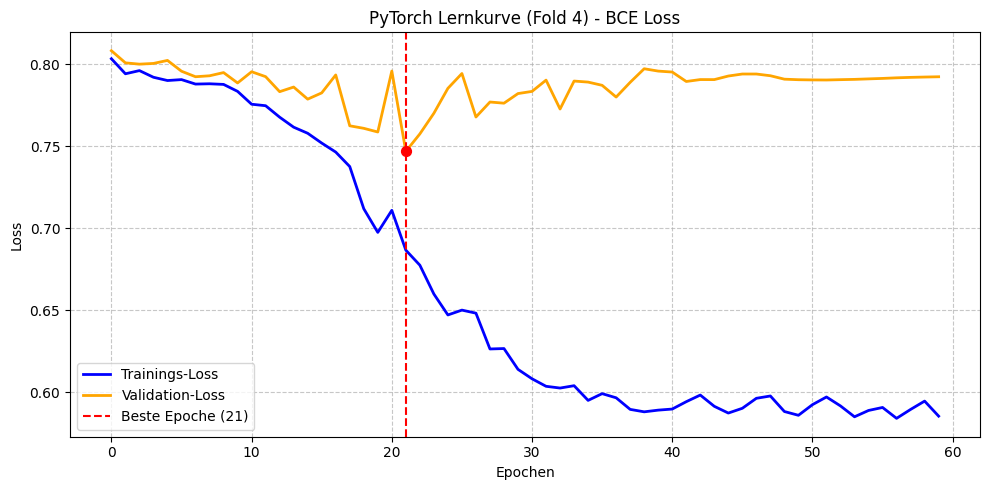

🏋️ Trainiere Fold 5/10...
   🎯 Beste Gewichte in Epoche 45 gefunden (Validation-Loss: 0.6291)


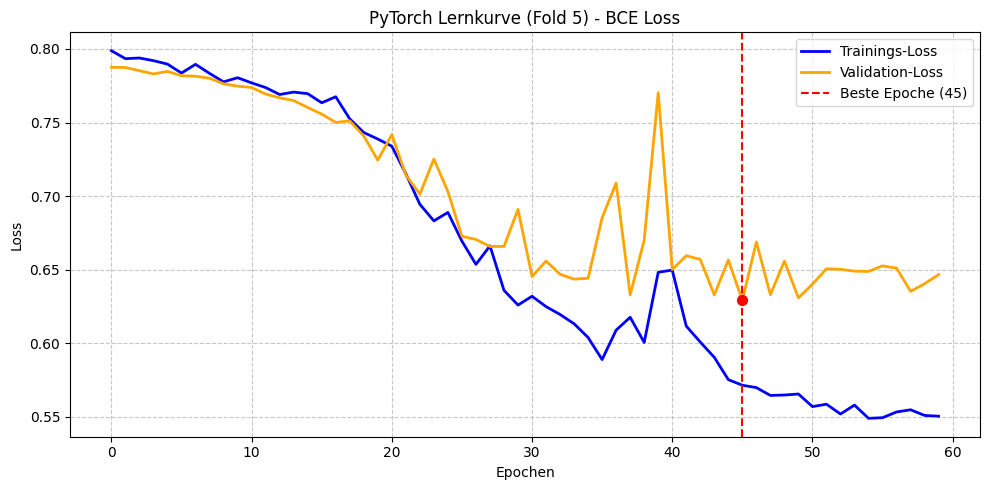

🏋️ Trainiere Fold 6/10...
   🎯 Beste Gewichte in Epoche 46 gefunden (Validation-Loss: 0.6374)


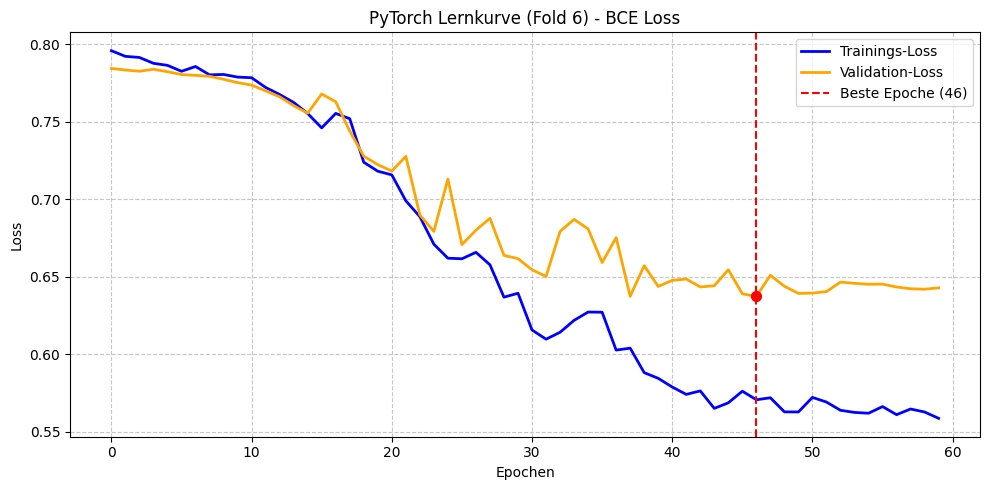

🏋️ Trainiere Fold 7/10...
   🎯 Beste Gewichte in Epoche 37 gefunden (Validation-Loss: 0.6371)


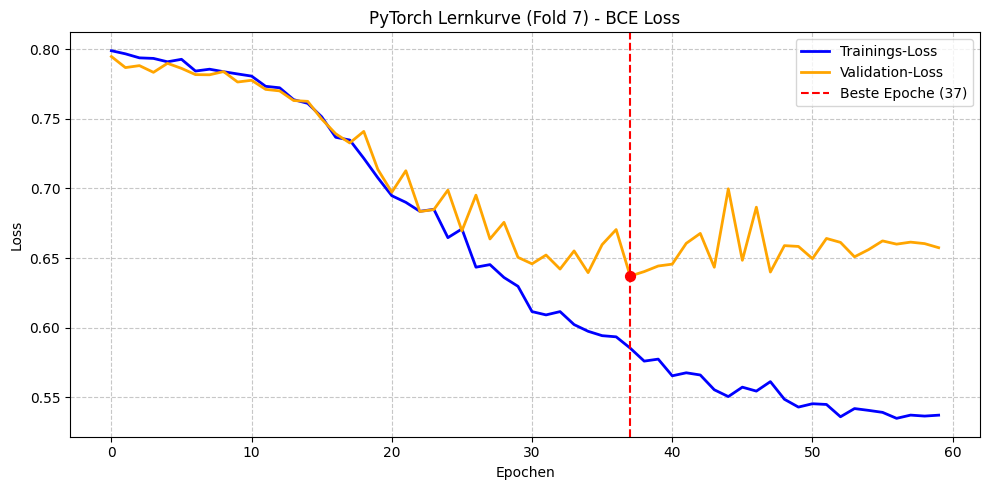

🏋️ Trainiere Fold 8/10...
   🎯 Beste Gewichte in Epoche 30 gefunden (Validation-Loss: 0.6821)


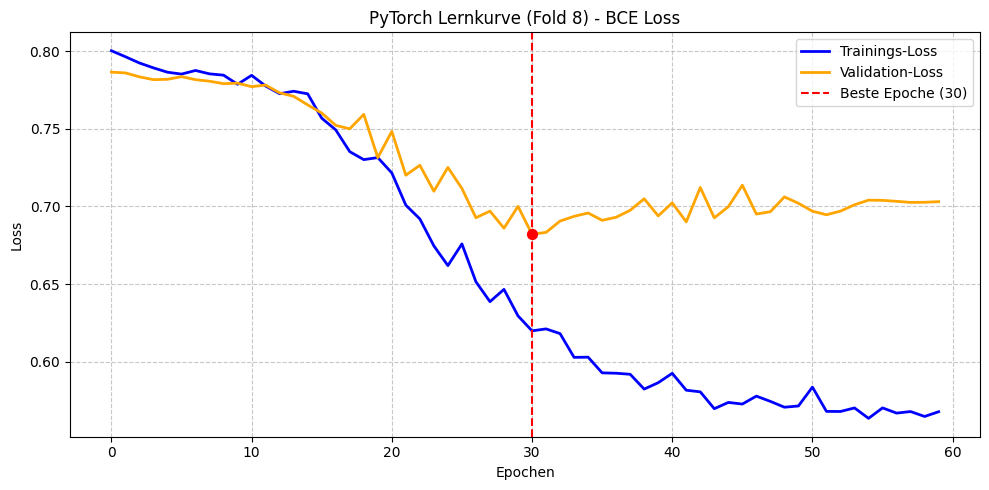

🏋️ Trainiere Fold 9/10...
   🎯 Beste Gewichte in Epoche 39 gefunden (Validation-Loss: 0.6712)


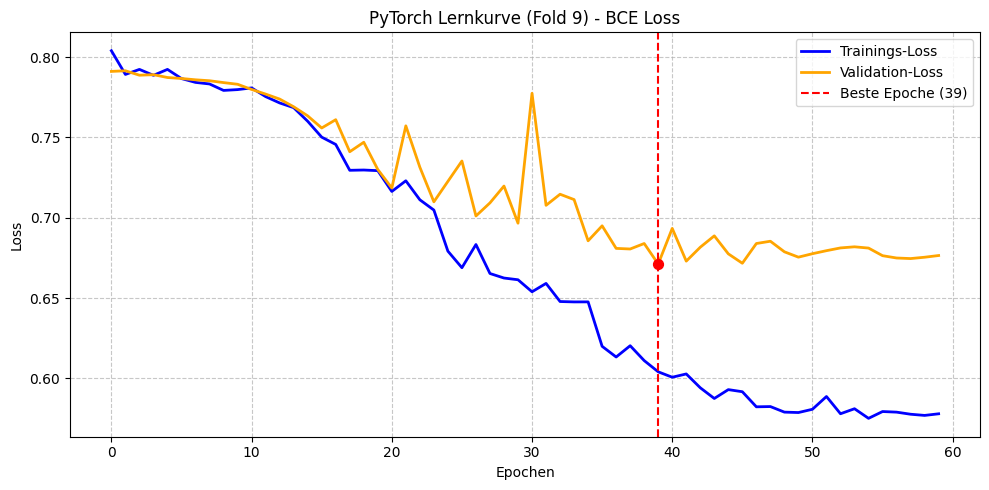

🏋️ Trainiere Fold 10/10...
   🎯 Beste Gewichte in Epoche 43 gefunden (Validation-Loss: 0.6314)


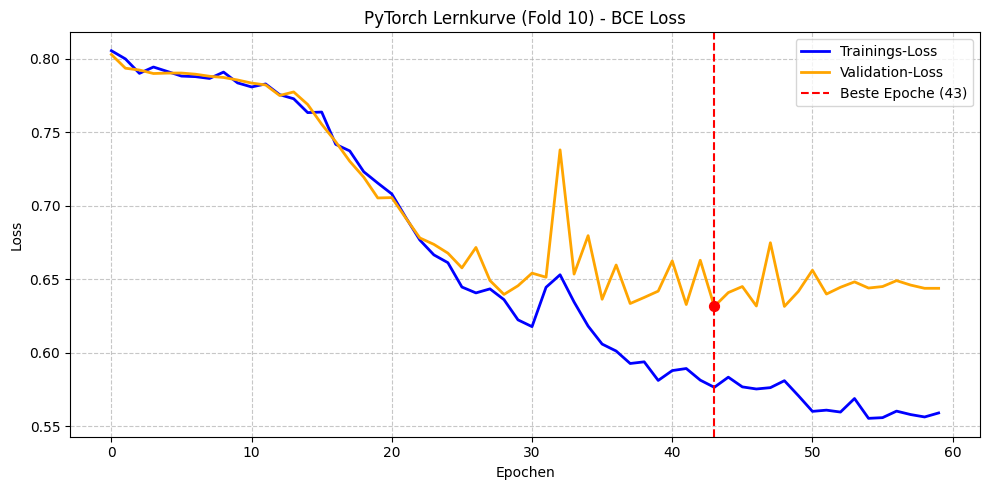


📊 REPRODUZIERBARER GESAMT-BERICHT (PyTorch MLP mit pos_weight):
                       precision    recall  f1-score   support

Algorithm Development       0.92      0.75      0.83       498
 Hardware Development       0.52      0.64      0.57       174
 Software Development       0.57      0.59      0.58       351
           User Study       0.83      0.64      0.72       389
        Dataset Paper       0.18      0.79      0.30        57
    Literature Review       0.09      0.50      0.16        12
     is_dataset_paper       0.12      0.72      0.21        18
          open_access       0.61      0.65      0.63       318
        code_required       0.97      0.78      0.87       569
       code_available       0.34      0.68      0.45       157
             code_url       0.36      0.66      0.47       172
        data_required       0.90      0.81      0.85       475
       data_available       0.52      0.80      0.63       202
             data_url       0.31      0.68      0.43

In [30]:
"""
Zweck dieser Zelle: Multi-Label-Klassifikation der 16 Paper-Typen und Metadaten mittels eines optimierten PyTorch MLPs.
Im Gegensatz zur Standard-Implementierung wird das extreme Klassen-Ungleichgewicht durch ein auf 25.0 gedeckeltes 'pos_weight' (Weight Clipping) kontrolliert, um False Positives bei den Mikro-Klassen effektiv zu dämpfen.
Ein dynamischer ReduceLROnPlateau-Scheduler verhindert in Kombination mit einer L2-Regulierung (weight_decay=1e-4) das Overfitting und friert den optimalen Modellzustand am tiefsten Validierungspunkt ein.
"""

import numpy as np
import json
import pandas as pd  
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt 
import copy # 
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, hamming_loss, accuracy_score
from sklearn.metrics import jaccard_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from tqdm import tqdm
import random #  

# --- CONFIG ---
N_FOLDS = 10                      #  Auf 10 Folds erhöht für maximale statistische Robustheit
EPOCHS = 60                       #  Auf 60 Epochen erhöht, um Scheduler Raum zu geben
BATCH_SIZE = 128                  
VALIDIERUNGS_METHODE = "cross_validation"
NUTZE_GEWICHTUNG = True
INITIAL_LR = 0.001                # 🔄 UNTERSCHIED: Explizite Konfig-Variable statt implizitem Kleinbuchstaben 'lr'

def set_deterministic_seeds(seed=42):
    """Fixiert alle Zufallsgeneratoren für absolute Reproduzierbarkeit."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  
    
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"🔒 Globaler Zufalls-Seed auf '{seed}' fixiert. Ergebnisse sind jetzt deterministisch!")

# JETZT DIE FUNKTION AUSFÜHREN
seed_to_use = globals().get('GLOBAL_SEED', 42)
set_deterministic_seeds(seed_to_use)

# --- 1. DATEN LADEN ---
X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')

with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    ML_COLUMNS = json.load(f)

# --- NEU: ANGEPASSTER KLASSIFIKATOR-NAME FÜR EIGENEN ORDNER ---
classifier_name = "PyTorch_BCE_MLP_Balanced" 

# Die tiefe Verzeichnisstruktur analog zu den Fusionsdaten
base_dir = PREDICTIONS_ML_ROOT / classifier_name / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
base_dir.mkdir(parents=True, exist_ok=True)

# Scanne das Verzeichnis nach dem höchsten x in Unterverzeichnissen Run x, x >= 1
existing_runs = [d.name for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("Run_")]
run_numbers = [int(name.split("_")[1]) for name in existing_runs if name.split("_")[1].isdigit()]
next_run = max(run_numbers) + 1 if run_numbers else 1

# Erstelle den spezifischen Run-Ordner
RUN_DIR = base_dir / f"Run_{next_run}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Starte PyTorch Training auf Device: {DEVICE}")
print(f"📊 Daten geladen (Studien: {X.shape[0]}, Features: {X.shape[1]}, Labels: {y.shape[1]})")
print(f"📁 Neuer Arbeitsordner erstellt: {RUN_DIR}\n")

# --- HEADER FÜR DIE TXT-DATEI VORBEREITEN ---
report_header = (
    f"=== RUN PARAMETER ===\n"
    f"Datenquelle: {DATEN_QUELLE}\n"
    f"Embed-Modell: {MODELL_NAME}\n"
    f"Chunking-Strategie: {STRATEGIE_NAME}\n"
    f"Pooling: {POOLING_STRATEGIE}\n"
    f"Evaluierung: {VALIDIERUNGS_METHODE}\n"
    f"Klassifikator: {classifier_name}\n"
    f"Gewichtung (pos_weight): {NUTZE_GEWICHTUNG} (Clipped at 25.0)\n" 
    f"Epochen: {EPOCHS}\n"
    f"Batch Size: {BATCH_SIZE}\n"
    f"=====================\n\n"
)

# --- 3. PYTORCH DATASET DEFINIEREN ---
class PaperDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.float32)
        
    def __len__(self):
        return len(self.features)
        
    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

# --- 4. DAS NEURONALE NETZ (MLP) ---
class MultiLabelMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(MultiLabelMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3), 
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, output_dim) 
        )

    def forward(self, x):
        return self.network(x)

# --- 5. CROSS VALIDATION SCHLEIFE ---
mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
oof_predictions = np.zeros_like(y)
hamming_losses = []

best_epochs_per_fold = [] # 🔄 BONUS: Das leere Notizbuch VOR der Schleife erstellen

for fold, (train_idx, test_idx) in enumerate(mskf.split(X, y)):
    print(f"🏋️ Trainiere Fold {fold + 1}/{N_FOLDS}...")
    
    X_train_fold, X_test_fold = X[train_idx], X[test_idx] 
    y_train_fold, y_test_fold = y[train_idx], y[test_idx] 
    
    train_dataset = PaperDataset(X_train_fold, y_train_fold) 
    test_dataset = PaperDataset(X_test_fold, y_test_fold)   
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    torch.manual_seed(42)
    
    pos_counts = np.sum(y_train_fold, axis=0)
    neg_counts = len(y_train_fold) - pos_counts
    pos_counts = np.clip(pos_counts, 1, None)
    raw_weights = neg_counts / pos_counts 
    pos_weights = torch.tensor(np.clip(raw_weights, None, 25.0), dtype=torch.float32).to(DEVICE)
    
    model = MultiLabelMLP(input_dim=X.shape[1], output_dim=y.shape[1]).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)
    optimizer = optim.Adam(model.parameters(), lr=INITIAL_LR, weight_decay=1e-4) # L2 Regulierung um Overfitting zu vermeiden
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3) 
    
    fold_train_losses = []
    fold_val_losses = []
    
    best_val_loss = float('inf')
    best_model_wts = copy.deepcopy(model.state_dict())
    best_epoch = 0  
    
    for epoch in range(EPOCHS):
        # 1. Training Pass
        model.train()
        running_train_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * batch_x.size(0)
            
        epoch_train_loss = running_train_loss / len(train_dataset)
        fold_train_losses.append(epoch_train_loss)
        
        # 2. Validation Pass
        model.eval()
        running_val_loss = 0.0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
                logits = model(batch_x)
                val_loss = criterion(logits, batch_y)
                running_val_loss += val_loss.item() * batch_x.size(0)
                
        epoch_val_loss = running_val_loss / len(test_dataset)
        fold_val_losses.append(epoch_val_loss)
        
        scheduler.step(epoch_val_loss) 
        
        if epoch_val_loss < best_val_loss: 
            best_val_loss = epoch_val_loss 
            best_model_wts = copy.deepcopy(model.state_dict()) 
            best_epoch = epoch  

    best_epochs_per_fold.append(best_epoch) # 🔄 BONUS: Am Ende des Folds die beste Epoche im Notizbuch notieren

    print(f"   🎯 Beste Gewichte in Epoche {best_epoch} gefunden (Validation-Loss: {best_val_loss:.4f})")
    
    # --- LERNKURVEN PLOTTEN ---
    plt.figure(figsize=(10, 5))
    plt.plot(fold_train_losses, label='Trainings-Loss', color='blue', linewidth=2)
    plt.plot(fold_val_losses, label='Validation-Loss', color='orange', linewidth=2)
    
    plt.axvline(x=best_epoch, color='red', linestyle='--', linewidth=1.5, 
                label=f'Beste Epoche ({best_epoch})')
    plt.scatter(best_epoch, best_val_loss, color='red', s=50, zorder=5)
    
    plt.title(f"PyTorch Lernkurve (Fold {fold+1}) - BCE Loss")
    plt.xlabel("Epochen")
    plt.ylabel("Loss")
    plt.legend() 
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    
    graph_path = RUN_DIR / f"Run_{next_run}_Learning_Curve_Fold-{fold+1}.png"
    plt.savefig(graph_path, dpi=300, bbox_inches='tight')
    plt.show() 

    # --- FINALE EVALUIERUNG ---
    model.load_state_dict(best_model_wts)  # Laden der Knoten Gewichte, wo val_loss am niedrigsten war
    model.eval()
    fold_preds = []
    with torch.no_grad():
        for batch_x, _ in test_loader:
            batch_x = batch_x.to(DEVICE)
            logits = model(batch_x)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).int().cpu().numpy()
            fold_preds.extend(preds)
            
    fold_preds = np.array(fold_preds)
    oof_predictions[test_idx] = fold_preds
    hamming_losses.append(hamming_loss(y_test_fold, fold_preds)) 

# --- 6. AUSWERTUNG ---
report_str = classification_report(y, oof_predictions, target_names=ML_COLUMNS, zero_division=0)
mean_hamming = np.mean(hamming_losses)
std_hamming = np.std(hamming_losses)
exact_match = accuracy_score(y, oof_predictions)
jaccard = jaccard_score(y, oof_predictions, average='samples', zero_division=0)

# 🔄 BONUS: Verwandelt das Notizbuch in eine schöne Textzeile
epochs_doku = ", ".join([f"Fold {i+1}: Epoche {ep}" for i, ep in enumerate(best_epochs_per_fold)])

log_text = f"""📊 REPRODUZIERBARER GESAMT-BERICHT (PyTorch MLP mit pos_weight):
=================================================================
{report_str}
=================================================================
📌 Gewichts-Ursprung (Beste Epochen pro Fold):
{epochs_doku}
-----------------------------------------------------------------
📉 Mittlerer Hamming Loss: {mean_hamming:.4f} (± {std_hamming:.4f})
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity:  {jaccard:.4f} (Das Modell trifft im Schnitt {jaccard*100:.1f}% der relevanten Labels pro Studie!)
"""

print("\n" + log_text)

# --- 7. DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
daten_dict = {}
for i, col_name in enumerate(ML_COLUMNS):
    daten_dict[f"{col_name}_true"] = y[:, i]
    daten_dict[f"{col_name}_pred"] = oof_predictions[:, i]
pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)

with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
    f.write(report_header + log_text)

print(f"💾 ALLE DATEN ERFOLGREICH IN '{classifier_name}' GESPEICHERT!") 
print(f"📂 Zu finden unter: {RUN_DIR}")

In [10]:
"""
RandomForest_ML_Classifier
Zweck dieser Zelle:
Multi-Label-Klassifikation der 16 Paper-Typen und Metadaten mittels Random Forest.
LÖSUNG FÜR KLASSEN-UNGLEICHGEWICHT: Nutzt `class_weight='balanced'`.

🔄 STANDARDISIERT: Inklusive deterministischem Seed, N-Fold Cross-Validation, 
robuster predict_proba Auswertung und automatischer Run-Ordner-Generierung.
(Hinweis: Random Forests nutzen keine Epochen, daher entfallen Lernkurven und Checkpointing).
"""

import numpy as np
import json
import pandas as pd  
import random
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, hamming_loss, accuracy_score, jaccard_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

# --- CONFIG FÜR DIE EVALUIERUNG & ARCHITEKTUR ---
VALIDIERUNGS_METHODE = "cross_validation" # "holdout" oder "cross_validation"
N_FOLDS = 5                              
THRESHOLD = 0.5                           # 🔄 KORRIGIERT: Zurück auf 50%. Die Kombi aus 30% und 'balanced' erzeugte zu viele False Positives!
N_ESTIMATORS = 300                        # Anzahl der Bäume
MAX_DEPTH = 20                            # Verhindert tiefes Overfitting (Alternative zur L2-Regulierung)

# DETERMINISTISCHER START
def set_deterministic_seeds(seed=42):
    """Fixiert alle Zufallsgeneratoren für absolute Reproduzierbarkeit."""
    random.seed(seed)
    np.random.seed(seed)
    print(f"🔒 Zufalls-Seed auf '{seed}' fixiert. Ergebnisse sind deterministisch!")

seed_to_use = globals().get('GLOBAL_SEED', 42)
set_deterministic_seeds(seed_to_use)

# --- 1. DATEN VOM AKTUELLEN STRATEGIE-ORDNER LADEN ---
X = np.load(CURRENT_FUSION_PATH / 'X_data.npy')
y = np.load(CURRENT_FUSION_PATH / 'y_data.npy')

with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    ML_COLUMNS = json.load(f)

# --- 2. AUTOMATISCHE RUN-ORDNER LOGIK ---
classifier_id = "RandomForest_Balanced_Thresh"

# Die tiefe Verzeichnisstruktur analog zu den Fusionsdaten
base_dir = PREDICTIONS_ML_ROOT / classifier_id / DATEN_QUELLE / POOLING_STRATEGIE / MODELL_NAME / STRATEGIE_NAME
base_dir.mkdir(parents=True, exist_ok=True)

# Scanne den Ordner nach existierenden "Run_X" Ordnern und finde die höchste Nummer
existing_runs = [d.name for d in base_dir.iterdir() if d.is_dir() and d.name.startswith("Run_")]
run_numbers = [int(name.split("_")[1]) for name in existing_runs if name.split("_")[1].isdigit()]
next_run = max(run_numbers) + 1 if run_numbers else 1

# Erstelle den neuen Arbeitsordner für diesen Durchlauf
RUN_DIR = base_dir / f"Run_{next_run}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(f"📊 Daten erfolgreich geladen (Studien: {X.shape[0]}, Pooling-Dimension: {X.shape[1]})")
print(f"⚙️ Gewählte Evaluierung: {VALIDIERUNGS_METHODE.upper()}")
print(f"🌲 Architektur: Random Forest (Bäume: {N_ESTIMATORS}, Max-Tiefe: {MAX_DEPTH})")
print(f"⚖️ Gewichtung: class_weight='balanced'")
print(f"🎚️ Thresholding: {THRESHOLD*100}% für positive Klassifikation")
print(f"📁 Neuer Arbeitsordner erstellt: {RUN_DIR}\n")

# --- HEADER FÜR DIE TXT-DATEI VORBEREITEN ---
report_header = (
    f"=== RUN PARAMETER ===\n"
    f"Datenquelle: {DATEN_QUELLE}\n"
    f"Embed-Modell: {MODELL_NAME}\n"
    f"Chunking-Strategie: {STRATEGIE_NAME}\n"
    f"Pooling: {POOLING_STRATEGIE}\n"
    f"Evaluierung: {VALIDIERUNGS_METHODE}\n"
    f"Klassifikator: {classifier_id}\n"
    f"Zufalls-Seed: {seed_to_use}\n"
    f"Bäume (n_estimators): {N_ESTIMATORS}\n"
    f"Max Depth: {MAX_DEPTH}\n"
    f"Class Weighting: Balanced\n"
    f"Decision Threshold: {THRESHOLD}\n"
    f"=====================\n\n"
)

# --- 3. MODELL-PROTOTYP & ROBUSTE THRESHOLD FUNKTION ---
def create_new_rf():
    return RandomForestClassifier(
        n_estimators=N_ESTIMATORS, 
        max_depth=MAX_DEPTH,      
        class_weight='balanced', 
        random_state=seed_to_use,
        n_jobs=-1 # Nutzt alle CPU-Kerne           
    )

def apply_custom_threshold(rf_model, X_input, threshold):
    """
    Sichere Extraktion der Wahrscheinlichkeiten und Anwendung des Custom-Thresholds.
    Fängt Scikit-Learn Eigenheiten bei komplett fehlenden Klassen in einem CV-Fold ab.
    """
    probs_list = rf_model.predict_proba(X_input)
    predictions = np.zeros((X_input.shape[0], len(ML_COLUMNS)))
    
    for i in range(len(ML_COLUMNS)):
        # Prüfen, ob das Modell für dieses Label überhaupt beide Klassen (0 und 1) gesehen hat
        if len(rf_model.classes_[i]) == 2:
            prob_pos = probs_list[i][:, 1] # Wahrscheinlichkeit für "Yes" (Klasse 1)
        else:
            # Falls in einem extrem unausgeglichenen Fold nur 0en vorkamen
            class_val = rf_model.classes_[i][0]
            prob_pos = np.ones(X_input.shape[0]) if class_val == 1 else np.zeros(X_input.shape[0])
            
        # Anwenden des 50% Thresholds
        predictions[:, i] = (prob_pos >= threshold).astype(int)
        
    return predictions


# --- 4. EVALUIERUNG - LOGIK ---
if VALIDIERUNGS_METHODE == "holdout":
    # --- A: KLASSISCHER HOLDOUT SPLIT ---
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_to_use)
    
    rf = create_new_rf()
    print("🏋️ Starte RandomForest Training (Holdout Standard)...")
    rf.fit(X_train, y_train)
    
    # Vorhersage mit Custom Thresholding (z.B. 0.5)
    predictions = apply_custom_threshold(rf, X_test, THRESHOLD)
    
    # Auswertung
    report_str = classification_report(y_test, predictions, target_names=ML_COLUMNS, zero_division=0)
    h_loss = hamming_loss(y_test, predictions)
    exact_match = accuracy_score(y_test, predictions)
    jaccard = jaccard_score(y_test, predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 KLASSIFIZIERUNGS-BERICHT (Holdout 80/20):
=================================================================
{report_str}
=================================================================
📉 Hamming Loss: {h_loss:.4f}
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} ({jaccard*100:.1f}%)
"""
    print(log_text)
    
    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y_test[:, i]
        daten_dict[f"{col_name}_pred"] = predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"\n💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

elif VALIDIERUNGS_METHODE == "cross_validation":
    # --- B: N-FOLD CROSS VALIDATION ---
    print(f"🔄 Starte {N_FOLDS}-Fold Multi-Label Cross-Validation...")
    
    mskf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed_to_use)
    
    oof_predictions = np.zeros_like(y)
    hamming_losses = []
    
    for fold, (train_idx, test_idx) in enumerate(mskf.split(X, y)):
        print(f"  🌲 Wachse Wald für Fold {fold + 1}/{N_FOLDS}...")
        
        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]
        
        rf_fold = create_new_rf()
        rf_fold.fit(X_train_fold, y_train_fold)
        
        # Vorhersage mit Custom Thresholding (z.B. 0.5)
        fold_preds = apply_custom_threshold(rf_fold, X_test_fold, THRESHOLD)
        
        oof_predictions[test_idx] = fold_preds
        hamming_losses.append(hamming_loss(y_test_fold, fold_preds))
    
    # Auswertung
    report_str = classification_report(y, oof_predictions, target_names=ML_COLUMNS, zero_division=0)
    mean_hamming = np.mean(hamming_losses)
    std_hamming = np.std(hamming_losses)
    exact_match = accuracy_score(y, oof_predictions)
    jaccard = jaccard_score(y, oof_predictions, average='samples', zero_division=0)
    
    log_text = f"""📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Cross-Validation):
=================================================================
{report_str}
=================================================================
📉 Mittlerer Hamming Loss: {mean_hamming:.4f} (± {std_hamming:.4f})
🎯 Subset Accuracy (Strenge Metrik): {exact_match:.4f} ({exact_match*100:.1f}%)
🤝 Jaccard Similarity (Teilpunkte):  {jaccard:.4f} (Das Modell trifft im Schnitt {jaccard*100:.1f}% der relevanten Labels pro Studie!)
"""
    print("\n" + log_text)
    
    # --- DATEN LOKAL IM RUN-ORDNER SPEICHERN ---
    daten_dict = {}
    for i, col_name in enumerate(ML_COLUMNS):
        daten_dict[f"{col_name}_true"] = y[:, i]
        daten_dict[f"{col_name}_pred"] = oof_predictions[:, i]
    pd.DataFrame(daten_dict).to_csv(RUN_DIR / f"Run_{next_run}.csv", index=False)
    
    with open(RUN_DIR / f"Run_{next_run}.txt", "w", encoding="utf-8") as f:
        f.write(report_header + log_text)
        
    print(f"💾 ALLE DATEN ERFOLGREICH GESPEICHERT!")
    print(f"📂 Zu finden unter: {RUN_DIR}")

🔒 Zufalls-Seed auf '42' fixiert. Ergebnisse sind deterministisch!
📊 Daten erfolgreich geladen (Studien: 654, Pooling-Dimension: 768)
⚙️ Gewählte Evaluierung: CROSS_VALIDATION
🌲 Architektur: Random Forest (Bäume: 300, Max-Tiefe: 20)
⚖️ Gewichtung: class_weight='balanced'
🎚️ Thresholding: 50.0% für positive Klassifikation
📁 Neuer Arbeitsordner erstellt: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/Predictions/RandomForest_Balanced_Thresh/markdown/max/nomic-embed-text-v2-moe/1200_chars_fixed_chunks/Run_2

🔄 Starte 5-Fold Multi-Label Cross-Validation...
  🌲 Wachse Wald für Fold 1/5...
  🌲 Wachse Wald für Fold 2/5...
  🌲 Wachse Wald für Fold 3/5...
  🌲 Wachse Wald für Fold 4/5...
  🌲 Wachse Wald für Fold 5/5...

📊 REPRODUZIERBARER GESAMT-BERICHT OVER ALL FOLDS (Cross-Validation):
                       precision    recall  f1-score   support

Algorithm Development       0.76      1.00      0.86       498
 Hardware Development       0.00      0.00      0.00       174
 Software Developme

In [33]:
"""
Zweck dieser Zelle:
Zero-Shot-Klassifikation mit Llama 3.2 (Version 3.0).
Inklusive dynamischer Pfadanpassung für die Trennung der Prompt-Techniken.
Dataset Paper ist exkludiert und die Aggregation nutzt das Klassensieger-Prinzip.
"""

import requests
import json
import os
import re
import datetime
import numpy as np
from tqdm.notebook import tqdm
from sklearn.metrics import classification_report

# --- 1. CONFIG & PFAD-STRUKTUR ---
LLM_LIMIT = 10 
OLLAMA_GENERATE_URL = "http://localhost:11434/api/generate"
LLM_MODELL = "llama3.2"

# Neue Steuerungs-Variable für die saubere Ordnertrennung
PROMPT_TECHNIQUE = "zero_shot"

# Aktualisierte Kategorien (OHNE Dataset Paper)
CATEGORIES = ["Algorithm Development", "Hardware Development", "Software Development", "User Study", "Literature Review"]

# Pfad-Hierarchie aufbauen
LLM_PRED_BASE_ROOT = BASE_DIR / "daten" / "predictions_llm"
CURRENT_LLM_PRED_PATH = LLM_PRED_BASE_ROOT / LLM_MODELL / PROMPT_TECHNIQUE / STRATEGIE_NAME

# Verzeichnisstruktur auf der Festplatte anlegen
for jahr in UNTERORDNER_JAHRE:
    (CURRENT_LLM_PRED_PATH / jahr).mkdir(parents=True, exist_ok=True)

def clean_and_parse_json(raw_response):
    """Extrahiert robust das JSON-Array, selbst wenn das LLM Markdown-Tags nutzt."""
    text = raw_response.strip()
    text = re.sub(r"```json\s*", "", text)
    text = re.sub(r"```\s*", "", text)
    
    match = re.search(r"\[.*\]", text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group(0))
        except json.JSONDecodeError:
            return []
    return []

def classify_chunk_with_llm(text_content):
    """Sendet einen Text-Chunk an Llama 3.2 und fordert eine reine Zero-Shot-JSON-Klassifikation."""
    prompt = f"""You are an expert academic classifier. Analyze the following text chunk from a research paper.
    Determine which of these categories apply to the text: {CATEGORIES}.
    A paper can have multiple categories (Multi-Label). If none apply, return an empty list.
    
    CRITICAL: You must respond ONLY with a valid JSON array of strings containing the matching categories. 
    Do not write any introduction, explanation, or markdown blocks.
    Example response: ["User Study", "Software Development"]
    
    Text chunk to analyze:
    {text_content}"""
    
    try:
        response = requests.post(OLLAMA_GENERATE_URL, json={
            "model": LLM_MODELL,
            "prompt": prompt,
            "stream": False,
            "options": {"temperature": 0.0} 
        }, timeout=15)
        
        return clean_and_parse_json(response.json()['response'])
    except Exception:
        return []

# --- 2. VERARBEITUNG MIT FORTSETZUNGS-LOGIK ---
print(f"🤖 Starte Transformer-Klassifikation...")
print(f"🛠️ Technik: {PROMPT_TECHNIQUE}")
print(f"📍 Zielordner: {CURRENT_LLM_PRED_PATH}")

y_true_llm = []
y_pred_llm = []
processed_studies = 0
stop_processing = False

for jahr in UNTERORDNER_JAHRE:
    if stop_processing: break
    source_dir = STUDIEN_ROOT / jahr
    if not source_dir.exists(): continue
    
    pdfs = sorted([f for f in os.listdir(source_dir) if f.endswith(".pdf")])
    
    for pdf in pdfs:
        if processed_studies >= LLM_LIMIT:
            stop_processing = True
            break
            
        paper_id_key = pdf.replace(".pdf", "").strip()
        match = master_label_df[master_label_df['paper_id'] == paper_id_key]
        if match.empty: continue 
        
        out_json_path = CURRENT_LLM_PRED_PATH / jahr / pdf.replace(".pdf", "_prediction.json")
        
        # Ground Truth holen und 'Dataset Paper' ignorieren
        row = match.iloc[0]
        paper_type_str = str(row['paper_type'])
        final_doc_true = [1 if cat in paper_type_str else 0 for cat in CATEGORIES]
        
        # FALL 1: Bereits verarbeitet (Fortsetzungs-Logik)
        # Wenn wir die Zelle erneut starten, wird der bereinigte Pfad ausgelesen
        if out_json_path.exists():
            with open(out_json_path, 'r', encoding='utf-8') as f:
                saved_data = json.load(f)
                saved_vector = saved_data["predictions"]["binary_vector"]
            
            y_true_llm.append(final_doc_true)
            y_pred_llm.append(saved_vector)
            processed_studies += 1
            continue
            
        # FALL 2: Neu analysieren
        chunks, pdf_internal_meta = extract_pdf_structure(source_dir / pdf)
        if not chunks: continue
        
        print(f"📄 Analysiere {pdf} ({len(chunks)} Chunks)...")
        document_votes = {cat: 0 for cat in CATEGORIES}
        
        for chunk in tqdm(chunks, desc="Klassifiziere Chunks", leave=False):
            predicted_cats = classify_chunk_with_llm(chunk['text'])
            for cat in predicted_cats:
                if cat in document_votes:
                    document_votes[cat] += 1
                    
        # --- AGGREGATION: KLASSENSIEGER-PRINZIP (RELATIVE MEHRHEIT) ---
        max_votes = max(document_votes.values())
        final_doc_pred = [0] * len(CATEGORIES)
        
        if max_votes > 0:
            # Aktiviert den Sieger sowie knappe Verfolger (Toleranz: 2 Stimmen)
            final_doc_pred = [1 if document_votes[cat] >= max(1, max_votes - 2) else 0 for cat in CATEGORIES]
        
        # ERGEBNIS IM NEUEN ZERO-SHOT ORDNER SPEICHERN
        with open(out_json_path, 'w', encoding='utf-8') as f:
            json.dump({
                "metadata": {
                    "source_filename": pdf,
                    "pdf_header_info": pdf_internal_meta,
                    "model": LLM_MODELL,
                    "prompt_technique": PROMPT_TECHNIQUE,
                    "strategy": STRATEGIE_NAME,
                    "timestamp": datetime.datetime.now().isoformat(),
                    "chunk_count": len(chunks),
                    "aggregation_strategy": "Relative Majority (Max Votes - 2 Tolerance)"
                },
                "votes_distribution": document_votes,
                "predictions": {
                    "binary_vector": final_doc_pred,
                    "active_categories": [CATEGORIES[i] for i, v in enumerate(final_doc_pred) if v == 1]
                }
            }, f, indent=4, ensure_ascii=False)
            
        y_true_llm.append(final_doc_true)
        y_pred_llm.append(final_doc_pred)
        processed_studies += 1

# --- 3. AUSWERTUNG ---
if y_true_llm:
    print(f"\n📊 KLASSIFIZIERUNGS-BERICHT ({LLM_MODELL} - {PROMPT_TECHNIQUE}):")
    print("-" * 65)
    print(classification_report(np.array(y_true_llm), np.array(y_pred_llm), target_names=CATEGORIES, zero_division=0))
    print("-" * 65)

🤖 Starte Transformer-Klassifikation...
🛠️ Technik: zero_shot
📍 Zielordner: /var/home/Mike-bazz/Dokumente/Meine_Bachelorarbeit/daten/predictions_llm/llama3.2/zero_shot/1200_chars_fixed_chunks
📄 Analysiere 2023_Dec_148.pdf (262 Chunks)...


Klassifiziere Chunks:   0%|          | 0/262 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [9]:
"""
Zweck dieser Zelle:
Robuste 16-Label Few-Shot-Klassifikation mit Llama 3.2 (Version 3.0) via Ollama.
Technik: Standard Few-Shot OHNE spezifische Keyword-Guidelines.
Speichert die Resultate sauber im vordefinierten CURRENT_PREDICTIONS_PATH ab.
Nutzt eine prozentuale Schwellenwert-Aggregation, um echtes Multi-Label-Verhalten zu erzwingen.
"""

import requests
import json
import os
import re
import datetime
import numpy as np
from tqdm.notebook import tqdm
from sklearn.metrics import classification_report

# --- 1. CONFIG & PFADE AUS DEM COCKPIT ---
LLM_LIMIT = 130 
OLLAMA_GENERATE_URL = "http://localhost:11434/api/generate"
LLM_MODELL = LLM_MODELL_NAME  # Nutzt die globale Variable aus deinem Cockpit

# 🔄 GEÄNDERT: Neue Prompt-Technik ohne Keywords
PROMPT_TECHNIQUE = "few_shot_standard"

# Dynamische Bestimmung der Dateiendung
DATEI_ENDUNG = ".md" if DATEN_QUELLE == "markdown" else ".pdf"
QUELL_ORDNER_ROOT = MARKDOWN_ROOT if DATEN_QUELLE == "markdown" else STUDIEN_ROOT

# Lädt alle 16 Labels exakt so, wie sie in den anderen ML-Segmenten definiert sind
with open(CURRENT_FUSION_PATH / 'y_columns.json', 'r', encoding='utf-8') as f:
    CATEGORIES = json.load(f)

# Die Resultate werden direkt unter CURRENT_PREDICTIONS_PATH organisiert
TARGET_OUTPUT_ROOT = CURRENT_PREDICTIONS_PATH / PROMPT_TECHNIQUE / STRATEGIE_NAME

# Verzeichnisstruktur für die Jahre anlegen
for jahr in UNTERORDNER_JAHRE:
    (TARGET_OUTPUT_ROOT / jahr).mkdir(parents=True, exist_ok=True)

def clean_and_parse_json(raw_response):
    """Extrahiert robust das JSON-Array, selbst wenn das LLM Markdown-Tags nutzt."""
    text = raw_response.strip()
    text = re.sub(r"```json\s*", "", text)
    text = re.sub(r"```\s*", "", text)
    
    match = re.search(r"\[.*\]", text, re.DOTALL)
    if match:
        try:
            return json.loads(match.group(0))
        except json.JSONDecodeError:
            return []
    return []

def classify_chunk_with_llm(text_content):
    """Sendet den Text an Ollama unter Verwendung eines Standard-Few-Shot-Prompts ohne Keyword-Hilfen."""
    
    # 🔄 GEÄNDERT: Keyword-Guidelines komplett entfernt. Der Prompt ist jetzt viel schlanker.
    prompt = f"""You are an expert academic classifier trained to categorize research paper snippets across 16 dimensions.
    Analyze the given text chunk and determine which of these categories apply: {CATEGORIES}.
    A text chunk can have multiple categories assigned (Multi-Label Classification). If no category fits, return an empty list [].

    ---
    FEW-SHOT EXAMPLE 1 (Hardware, User Study & Artifacts):
    Input Text: "We designed a custom wearable sensor node using a flexible PCB layout. To evaluate the comfort, we recruited 15 participants for a user study. The dataset and firmware are available at https://github.com/project/core"
    Response: ["Hardware Development", "User Study", "code_required", "code_available", "code_url", "data_required", "data_available", "data_url", "hardware_required"]

    FEW-SHOT EXAMPLE 2 (Algorithm & Open Source):
    Input Text: "To minimize error, we introduce a novel loss function. The complete evaluation pipeline architecture has been uploaded to our public GitHub repository as an open-source library under open access terms."
    Response: ["Algorithm Development", "Software Development", "open_access", "code_required", "code_available", "code_url"]
    ---

    CRITICAL: You must respond ONLY with a valid JSON array of strings containing the matching categories from the allowed list. 
    Do not write any introduction, conversational filler, markdown formatting (like ```json), or explanations.

    Text chunk to analyze:
    {text_content}"""
    
    try:
        response = requests.post(OLLAMA_GENERATE_URL, json={
            "model": LLM_MODELL,
            "prompt": prompt,
            "stream": False,
            "options": {"temperature": 0.0} 
        }, timeout=15)
        
        return clean_and_parse_json(response.json()['response'])
    except Exception:
        return []

# --- 2. MAIN PIPELINE ---
print(f"🤖 Starte Llama 3.2 Multi-Label Klassifikation...")
print(f"📂 Modus: Erkennung basiert auf '{DATEN_QUELLE.upper()}'-Dateien (Suche nach *{DATEI_ENDUNG})")
print(f"🛠️ Technik: {PROMPT_TECHNIQUE}")
print(f"📍 Zielordner (CURRENT_PREDICTIONS_PATH): {TARGET_OUTPUT_ROOT}")

y_true_llm = []
y_pred_llm = []
processed_studies = 0
stop_processing = False

for jahr in UNTERORDNER_JAHRE:
    if stop_processing: break
    source_dir = QUELL_ORDNER_ROOT / jahr
    if not source_dir.exists(): continue
    
    studien_dateien = sorted([f for f in os.listdir(source_dir) if f.endswith(DATEI_ENDUNG)])
    
    for datei in studien_dateien:
        if processed_studies >= LLM_LIMIT:
            stop_processing = True
            break
            
        paper_id_key = datei.replace(DATEI_ENDUNG, "").strip()
        match = master_label_df[master_label_df['paper_id'] == paper_id_key]
        if match.empty: continue 
        
        out_json_path = TARGET_OUTPUT_ROOT / jahr / datei.replace(DATEI_ENDUNG, "_prediction.json")
        
        # Ground Truth für alle 16 Labels dynamisch extrahieren & flexibel parsen
        row = match.iloc[0]
        final_doc_true = []
        for cat in CATEGORIES:
            if cat in row:
                val = str(row[cat]).strip().lower()
                if val in ['1', '1.0', 'yes', 'true']:
                    final_doc_true.append(1)
                else:
                    final_doc_true.append(0)
            else:
                final_doc_true.append(1 if cat in str(row.to_dict()) else 0)
        
        # Fortsetzungs-Logik bei wiederholtem Start
        if out_json_path.exists():
            with open(out_json_path, 'r', encoding='utf-8') as f:
                saved_data = json.load(f)
                saved_vector = saved_data["predictions"]["binary_vector"]
            
            y_true_llm.append(final_doc_true)
            y_pred_llm.append(saved_vector)
            processed_studies += 1
            continue
        
        # NEUBERECHNUNG ÜBER DIE UNIVERSELLE EXTRAKTIONS-FUNKTION
        chunks, internal_meta = extract_pdf_structure(source_dir / datei)
        if not chunks: continue
        
        print(f"📄 Analysiere {datei} ({len(chunks)} Chunks)...")
        document_votes = {cat: 0 for cat in CATEGORIES}
        
        for chunk in tqdm(chunks, desc="Klassifiziere Chunks", leave=False):
            predicted_cats = classify_chunk_with_llm(chunk['text'])
            for cat in predicted_cats:
                if cat in document_votes:
                    document_votes[cat] += 1
                    
        # Prozent-Schwelle (Threshold)
        total_chunks = len(chunks)
        final_doc_pred = [0] * len(CATEGORIES)
        
        for i, cat in enumerate(CATEGORIES):
            votes_for_cat = document_votes[cat]
            if votes_for_cat > 0:
                activation_ratio = votes_for_cat / total_chunks
                if activation_ratio >= 0.15:  # 15% Schwelle für stabile Multi-Label-Erkennung
                    final_doc_pred[i] = 1
        
        # JSON im neuen, korrekten Pfad abspeichern
        with open(out_json_path, 'w', encoding='utf-8') as f:
            json.dump({
                "metadata": {
                    "source_filename": datei,
                    "extraction_meta": internal_meta,
                    "model": LLM_MODELL,
                    "prompt_technique": PROMPT_TECHNIQUE,
                    "strategy": STRATEGIE_NAME,
                    "timestamp": datetime.datetime.now().isoformat(),
                    "chunk_count": total_chunks,
                    "aggregation_strategy": "Percentage Threshold (>= 15% Chunk Frequency)"
                },
                "votes_distribution": document_votes,
                "predictions": {
                    "binary_vector": final_doc_pred,
                    "active_categories": [CATEGORIES[i] for i, v in enumerate(final_doc_pred) if v == 1]
                }
            }, f, indent=4, ensure_ascii=False)
            
        y_true_llm.append(final_doc_true)
        y_pred_llm.append(final_doc_pred)
        processed_studies += 1

# --- 3. EVALUIERUNG ---
if y_true_llm:
    print(f"\n📊 DYNAMISCHER KLASSIFIZIERUNGS-BERICHT ({LLM_MODELL} - Quelle: {DATEN_QUELLE.upper()}):")
    print("-" * 65)
    print(classification_report(np.array(y_true_llm), np.array(y_pred_llm), target_names=CATEGORIES, zero_division=0))
    print("-" * 65)

🤖 Starte Llama 3.2 Multi-Label Klassifikation...
📂 Modus: Erkennung basiert auf 'MARKDOWN'-Dateien (Suche nach *.md)
🛠️ Technik: few_shot_standard
📍 Zielordner (CURRENT_PREDICTIONS_PATH): /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/predictions_llm/markdown/llama3.2/few_shot_standard/1200_chars_fixed_chunks
📄 Analysiere 2023_Mar_005.md (124 Chunks)...


Klassifiziere Chunks:   0%|          | 0/124 [00:00<?, ?it/s]

📄 Analysiere 2023_Mar_006.md (168 Chunks)...


Klassifiziere Chunks:   0%|          | 0/168 [00:00<?, ?it/s]

📄 Analysiere 2023_Mar_007.md (198 Chunks)...


...

📄 Analysiere 2023_Mar_033.md (144 Chunks)...


Klassifiziere Chunks:   0%|          | 0/144 [00:00<?, ?it/s]

📄 Analysiere 2023_Mar_034.md (115 Chunks)...


Klassifiziere Chunks:   0%|          | 0/115 [00:00<?, ?it/s]


📊 DYNAMISCHER KLASSIFIZIERUNGS-BERICHT (llama3.2 - Quelle: MARKDOWN):
-----------------------------------------------------------------
                       precision    recall  f1-score   support

Algorithm Development       0.85      0.98      0.91        97
 Hardware Development       0.73      0.44      0.55        43
 Software Development       0.49      0.64      0.56        64
           User Study       0.83      0.76      0.79        76
        Dataset Paper       0.05      1.00      0.10         7
    Literature Review       0.00      0.00      0.00         0
     is_dataset_paper       0.00      0.00      0.00         1
          open_access       0.30      0.06      0.10        50
        code_required       0.91      0.34      0.49       115
       code_available       0.00      0.00      0.00        23
             code_url       0.00      0.00      0.00         0
        data_required       1.00      0.02      0.04        88
       data_available       0.09      0.27 

📊 Generiere Konfusionsmatrizen für 16 Labels (llama3.2 - Quelle: MARKDOWN)...
💾 Grafik erfolgreich gespeichert unter: /var/mnt/2TB/Dokumente/Meine_Bachelorarbeit/daten/predictions_llm/markdown/llama3.2/few_shot_standard/1200_chars_fixed_chunks


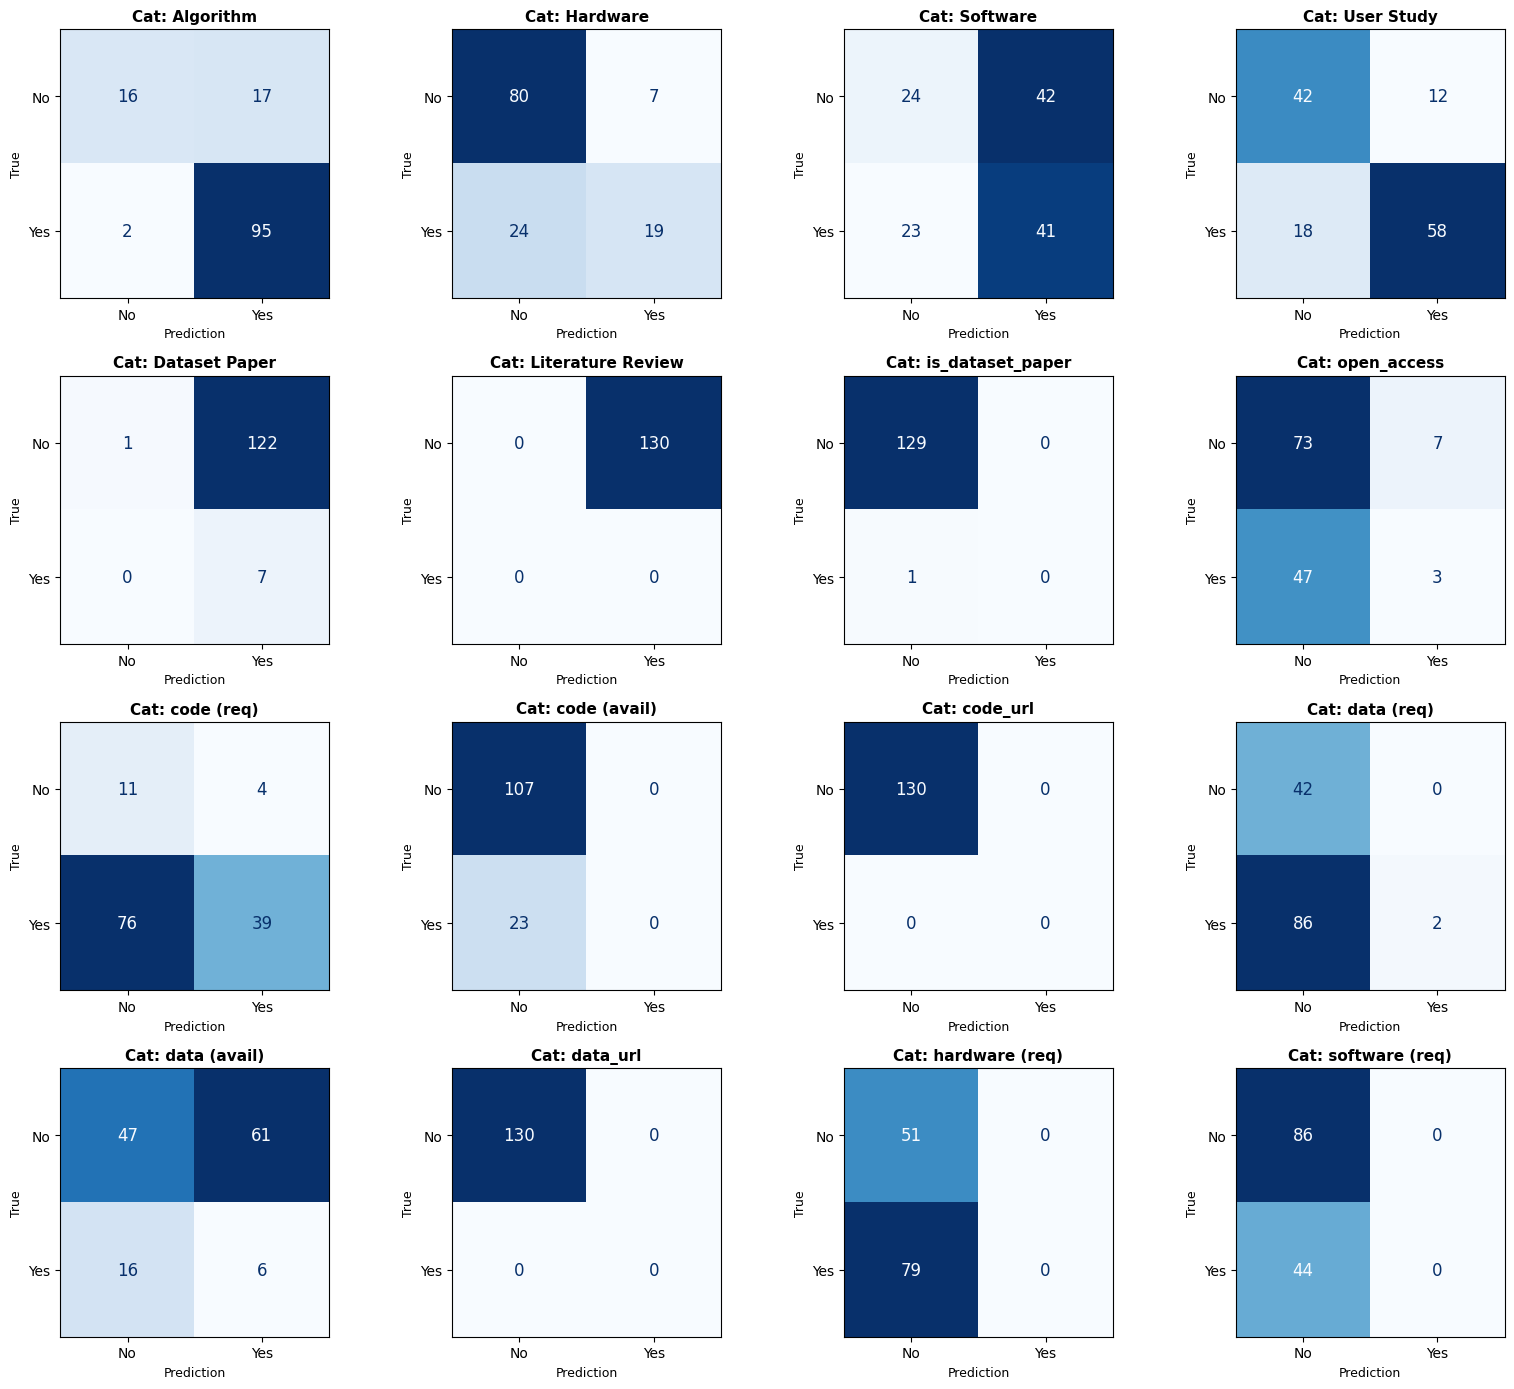

In [10]:
"""
Zweck dieser Zelle:
Berechnung und Visualisierung der Multilabel-Konfusionsmatrizen für das Llama 3.2-Segment.
Bildet alle 16 Labels in einem übersichtlichen 4x4-Raster ab und nutzt die dynamischen LLM-Ergebnisse.
"""

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay

# Sicherstellen, dass überhaupt LLM-Vorhersagen berechnet wurden
if not y_true_llm or not y_pred_llm:
    print("⚠️ Keine LLM-Vorhersagedaten vorhanden. Bitte führe zuerst das Llama 3.2 Segment aus!")
else:
    # Konfusionsmatrizen basierend auf den dynamischen LLM-Listen berechnen
    y_true_arr = np.array(y_true_llm)
    y_pred_arr = np.array(y_pred_llm)
    mcm = multilabel_confusion_matrix(y_true_arr, y_pred_arr)

    # Layout-Einstellungen für alle 16 Labels (4x4 Grid)
    fig, axes = plt.subplots(4, 4, figsize=(16, 14))
    axes = axes.ravel()

    print(f"📊 Generiere Konfusionsmatrizen für {len(CATEGORIES)} Labels ({LLM_MODELL_NAME} - Quelle: {DATEN_QUELLE.upper()})...")

    for i, cat_name in enumerate(CATEGORIES):
        # Matrix für das aktuelle Label visualisieren
        disp = ConfusionMatrixDisplay(
            confusion_matrix=mcm[i], 
            display_labels=['No', 'Yes']
        )
        
        # Plotting im jeweiligen Subplot mit harmonischem Farbverlauf (Blues/Greens)
        disp.plot(ax=axes[i], values_format='d', cmap='Blues', colorbar=False)
        
        # Dynamische Titel-Verkürzung für eine saubere Optik im Report
        short_title = cat_name.replace(" Development", "").replace("_required", " (req)").replace("_available", " (avail)")
        
        # Titel und Achsenbeschriftung präzise anpassen
        axes[i].set_title(f"Cat: {short_title}", fontsize=11, fontweight='bold')
        axes[i].set_xlabel('Prediction', fontsize=9)
        axes[i].set_ylabel('True', fontsize=9)
        
        # Text-Layout innerhalb der Matrizen optimieren (Schriftgröße der Zahlen)
        for text in axes[i].texts:
            text.set_fontsize(12)

    # Eventuell ungenutzte Subplots ausblenden (falls mal weniger als 16 Labels vorhanden sind)
    for j in range(len(CATEGORIES), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    
    # Optional: Direkt im aktuellen RUN_DIR des LLMs abspeichern
    if 'TARGET_OUTPUT_ROOT' in globals():
        plt.savefig(TARGET_OUTPUT_ROOT / f"Confusion_Matrices_16_Labels.png", dpi=300, bbox_inches='tight')
        print(f"💾 Grafik erfolgreich gespeichert unter: {TARGET_OUTPUT_ROOT}")
        
    plt.show()